# SPARCS Length-of-Stay Prediction and Bed-Capacity Optimization

**Data:** New York SPARCS inpatient discharges, 2015 (351,586 discharges, 34 raw columns, 59 facility names, 25 counties).
**Goal:** (1) understand and clean the data, (2) predict hospital length of stay (LOS) in days using only information plausibly known at admission, and (3) feed the predictions into an *illustrative* integer program that allocates staffed beds across hospitals.

---

### Headline results

| Topic | Result |
|---|---|
| LOS distribution | Strongly right-skewed: mean 5.31 days, median 3, 1.43% of stays exceed 30 days |
| Best admission-time model | **HistGB Poisson, feature set A**, selected on validation data |
| Final test performance | MAE **3.61** days, RMSE **7.51**, R² **0.09**, bias -0.01 days |
| Reference point | Validation mean-only baseline: MAE 3.98, RMSE 7.69 |
| Weak spot | Stays longer than 20 days are underpredicted by about **28 days** on average |
| Most influential feature | `permanent_facility_id` (largest mean absolute SHAP value) |
| Bed-allocation scenario | 5,449 beds cover **90.4%** of 1.87 million reference bed-days |

### Contents

1. [Setup and data loading](#sec1)
2. [Data-quality audit](#sec2)
3. [Data cleaning and feature engineering](#sec3)
4. [Target variable: length of stay](#sec4)
5. [Exploratory analysis of predictors](#sec5)
6. [Feature-timing audit and data splits](#sec6)
7. [Model development and validation](#sec7)
8. [Final evaluation on the held-out test set](#sec8)
9. [Model interpretation](#sec9)
10. [Bed-day planning and optimization scenario](#sec10)
11. [Summary, limitations and next steps](#sec11)

> **How to read this notebook:** code cells are unchanged. Each **Results** cell sits directly below the output it summarizes and quotes the numbers from the saved run. Re-running with different data or seeds will change those numbers.

<a id="sec1"></a>
## 1. Setup and data loading

Import libraries, load `sparcs.csv`, and take a first look at the structure and summary statistics.

In [1]:
# 1. Imports and settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')


In [2]:
# 2. Load data
df = pd.read_csv('sparcs.csv', low_memory=False)
print(f'Dimensions: {df.shape}')
display(df.head())
display(df.sample(min(5, len(df)), random_state=42))
df.info()


Dimensions: (351586, 34)


,hospital_service_area,hospital_county,operating_certificate_number,permanent_facility_id,facility_name,age_group,zip_code_3_digits,gender,race,ethnicity,length_of_stay,type_of_admission,patient_disposition,discharge_year,ccs_diagnosis_code,ccs_diagnosis_description,ccs_procedure_code,ccs_procedure_description,apr_drg_code,apr_drg_description,apr_mdc_code,apr_mdc_description,apr_severity_of_illness_code,apr_severity_of_illness_description,apr_risk_of_mortality,apr_medical_surgical_description,payment_typology_1,payment_typology_2,payment_typology_3,birth_weight,abortion_edit_indicator,emergency_department_indicator,total_charges,total_costs
0,Western NY,Allegany,"226,700.00",37.00,Cuba Memorial Hospital Inc,70 or Older,147,F,White,Not Span/Hispanic,4,Urgent,Home or Self Care,2015,122,Pneumonia (except that caused by tuberculosis ...,0,NO PROC,139,Other pneumonia,4,Diseases and Disorders of the Respiratory System,2.00,Moderate,Minor,Medical,Medicare,Private Health Insurance,NaN,0.00,N,Y,"5,333.90","4,818.42"
1,Western NY,Allegany,"226,700.00",37.00,Cuba Memorial Hospital Inc,70 or Older,147,F,White,Not Span/Hispanic,4,Elective,Hosp Basd Medicare Approved Swing Bed,2015,55,Fluid and electrolyte disorders,0,NO PROC,422,Hypovolemia & related electrolyte disorders,10,"Endocrine, Nutritional and Metabolic Diseases ...",2.00,Moderate,Moderate,Medical,Medicare,NaN,NaN,0.00,N,Y,"4,865.99","4,588.78"
2,Western NY,Allegany,"226,700.00",37.00,Cuba Memorial Hospital Inc,70 or Older,147,F,White,Not Span/Hispanic,4,Urgent,Home or Self Care,2015,122,Pneumonia (except that caused by tuberculosis ...,202,ELECTROCARDIOGRAM,139,Other pneumonia,4,Diseases and Disorders of the Respiratory System,1.00,Minor,Minor,Medical,Medicare,Private Health Insurance,NaN,0.00,N,Y,"5,901.54","5,559.56"
3,Western NY,Allegany,"226,700.00",37.00,Cuba Memorial Hospital Inc,50 to 69,147,F,White,Not Span/Hispanic,2,Elective,Home or Self Care,2015,55,Fluid and electrolyte disorders,0,NO PROC,249,"Other gastroenteritis, nausa & vomiting",6,Diseases and Disorders of the Digestive System,2.00,Moderate,Minor,Medical,Medicare,NaN,NaN,0.00,N,Y,"3,619.08","3,567.25"
4,Western NY,Allegany,"226,700.00",37.00,Cuba Memorial Hospital Inc,70 or Older,147,M,White,Not Span/Hispanic,2,Elective,Home or Self Care,2015,122,Pneumonia (except that caused by tuberculosis ...,0,NO PROC,139,Other pneumonia,4,Diseases and Disorders of the Respiratory System,1.00,Minor,Moderate,Medical,Medicare,Blue Cross/Blue Shield,Private Health Insurance,0.00,N,Y,"3,185.87","3,167.89"


,hospital_service_area,hospital_county,operating_certificate_number,permanent_facility_id,facility_name,age_group,zip_code_3_digits,gender,race,ethnicity,length_of_stay,type_of_admission,patient_disposition,discharge_year,ccs_diagnosis_code,ccs_diagnosis_description,ccs_procedure_code,ccs_procedure_description,apr_drg_code,apr_drg_description,apr_mdc_code,apr_mdc_description,apr_severity_of_illness_code,apr_severity_of_illness_description,apr_risk_of_mortality,apr_medical_surgical_description,payment_typology_1,payment_typology_2,payment_typology_3,birth_weight,abortion_edit_indicator,emergency_department_indicator,total_charges,total_costs
233511,Finger Lakes,Monroe,"2,701,005.00",413.00,Strong Memorial Hospital,50 to 69,146,M,White,Not Span/Hispanic,6,Emergency,Home or Self Care,2015,100,Acute myocardial infarction,45,PERC TRANSLUM COR ANGIO,174,Percutaneous coronary intervention w AMI,5,Diseases and Disorders of the Circulatory System,2.00,Moderate,Major,Surgical,Medicare,Medicare,Self-Pay,0.00,N,Y,"46,186.53","21,409.17"
154123,Western NY,Erie,"1,401,014.00","3,067.00",Millard Fillmore Suburban Hospital,50 to 69,141,M,White,Not Span/Hispanic,4,Elective,Skilled Nursing Home,2015,203,Osteoarthritis,153,"HIP REPLACEMENT,TOT/PRT",301,Hip joint replacement,8,Diseases and Disorders of the Musculoskeletal ...,1.00,Minor,Minor,Surgical,Blue Cross/Blue Shield,Self-Pay,NaN,0.00,N,N,"57,305.04","23,231.07"
342982,Central NY,Cayuga,"501,000.00",85.00,Auburn Community Hospital,50 to 69,130,M,White,Not Span/Hispanic,6,Elective,Home or Self Care,2015,657,Mood disorders,0,NO PROC,751,Major depressive disorders & other/unspecified...,19,Mental Diseases and Disorders,2.00,Moderate,Minor,Medical,Medicare,NaN,NaN,0.00,N,N,"10,198.50","3,830.53"
245395,Finger Lakes,Monroe,"2,701,005.00",413.00,Strong Memorial Hospital,0 to 17,146,F,Other Race,Not Span/Hispanic,12,Emergency,Home or Self Care,2015,2,Septicemia (except in labor),89,EXPLORATORY LAPAROTOMY,710,Infectious & parasitic diseases including HIV ...,18,"Infectious and Parasitic Diseases, Systemic or...",4.00,Extreme,Extreme,Surgical,Medicaid,Medicaid,Self-Pay,0.00,N,Y,"71,794.96","34,793.90"
212504,Finger Lakes,Monroe,"2,701,003.00",411.00,Rochester General Hospital,0 to 17,146,F,Black/African American,Not Span/Hispanic,1,Emergency,Home or Self Care,2015,128,Asthma,0,NO PROC,141,Asthma,4,Diseases and Disorders of the Respiratory System,1.00,Minor,Minor,Medical,Medicaid,NaN,NaN,0.00,N,Y,"9,539.23","3,332.29"


<class 'pandas.DataFrame'>
RangeIndex: 351586 entries, 0 to 351585
Data columns (total 34 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   hospital_service_area                350831 non-null  str    
 1   hospital_county                      350831 non-null  str    
 2   operating_certificate_number         350831 non-null  float64
 3   permanent_facility_id                350831 non-null  float64
 4   facility_name                        351586 non-null  str    
 5   age_group                            351586 non-null  str    
 6   zip_code_3_digits                    347398 non-null  str    
 7   gender                               351586 non-null  str    
 8   race                                 351586 non-null  str    
 9   ethnicity                            351586 non-null  str    
 10  length_of_stay                       351586 non-null  str    
 11  type_of_admission       

In [3]:
# 3. Summaries
display(df.describe(include='all').T)

def split_cols(frame):
    num = frame.select_dtypes(include=np.number).columns.tolist()
    cat = [c for c in frame.columns if c not in num]
    return num, cat

numcols, catcols = split_cols(df)
print('Numeric:', numcols)
print('Categorical:', catcols)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hospital_service_area,350831,5,Western NY,163826,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hospital_county,350831,25,Erie,120512,NaN,NaN,NaN,NaN,NaN,NaN,NaN
operating_certificate_number,"350,831.00",NaN,NaN,NaN,"1,955,058.00","1,200,053.12","101,004.00","1,401,005.00","1,401,014.00","2,701,005.00","6,120,700.00"
permanent_facility_id,"350,831.00",NaN,NaN,NaN,473.86,721.42,12.00,207.00,292.00,413.00,"9,431.00"
facility_name,351586,59,Strong Memorial Hospital,38653,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_group,351586,5,70 or Older,106291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zip_code_3_digits,347398,43,142,65718,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,351586,3,F,199449,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,351586,4,White,282877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ethnicity,351586,4,Not Span/Hispanic,331910,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Numeric: ['operating_certificate_number', 'permanent_facility_id', 'discharge_year', 'ccs_diagnosis_code', 'ccs_procedure_code', 'apr_drg_code', 'apr_mdc_code', 'apr_severity_of_illness_code', 'birth_weight', 'total_charges', 'total_costs']
Categorical: ['hospital_service_area', 'hospital_county', 'facility_name', 'age_group', 'zip_code_3_digits', 'gender', 'race', 'ethnicity', 'length_of_stay', 'type_of_admission', 'patient_disposition', 'ccs_diagnosis_description', 'ccs_procedure_description', 'apr_drg_description', 'apr_mdc_description', 'apr_severity_of_illness_description', 'apr_risk_of_mortality', 'apr_medical_surgical_description', 'payment_typology_1', 'payment_typology_2', 'payment_typology_3', 'abortion_edit_indicator', 'emergency_department_indicator']


#### Results: dataset overview

| Property | Value |
|---|---|
| Shape | **351,586 rows x 34 columns** (one row per discharge) |
| Time span | Single year, 2015 |
| Column types | 11 numeric, 23 categorical (text) |
| Hospitals | 59 facility names, 25 counties, 5 service areas |
| Clinical groupings | 26 APR MDC categories, 316 APR DRGs, 262 CCS diagnoses, 227 CCS procedures |

**Things to notice**

- `length_of_stay` is read as *text* (120 distinct values) because the largest stays are coded as `120 +`. It is converted to a number in section 3.
- Several columns are IDs or codes stored as numbers (facility ID, certificate number, CCS and DRG codes). They are categories, not quantities, and are re-typed later.
- 755 rows have no hospital service area, county or facility ID (see section 2).

> **Takeaway:** the data is large enough for flexible models, but needs type fixes and a careful target definition before modeling.

<a id="sec2"></a>
## 2. Data-quality audit

Quantify missing values, apply the 50% drop rule, and check for duplicate rows.

,Missing Values,Missing perc
payment_typology_3,280222,79.70
payment_typology_2,129119,36.72
zip_code_3_digits,4188,1.19
hospital_service_area,755,0.21
hospital_county,755,0.21
operating_certificate_number,755,0.21
permanent_facility_id,755,0.21
apr_risk_of_mortality,25,0.01
apr_severity_of_illness_description,25,0.01
birth_weight,1,0.00


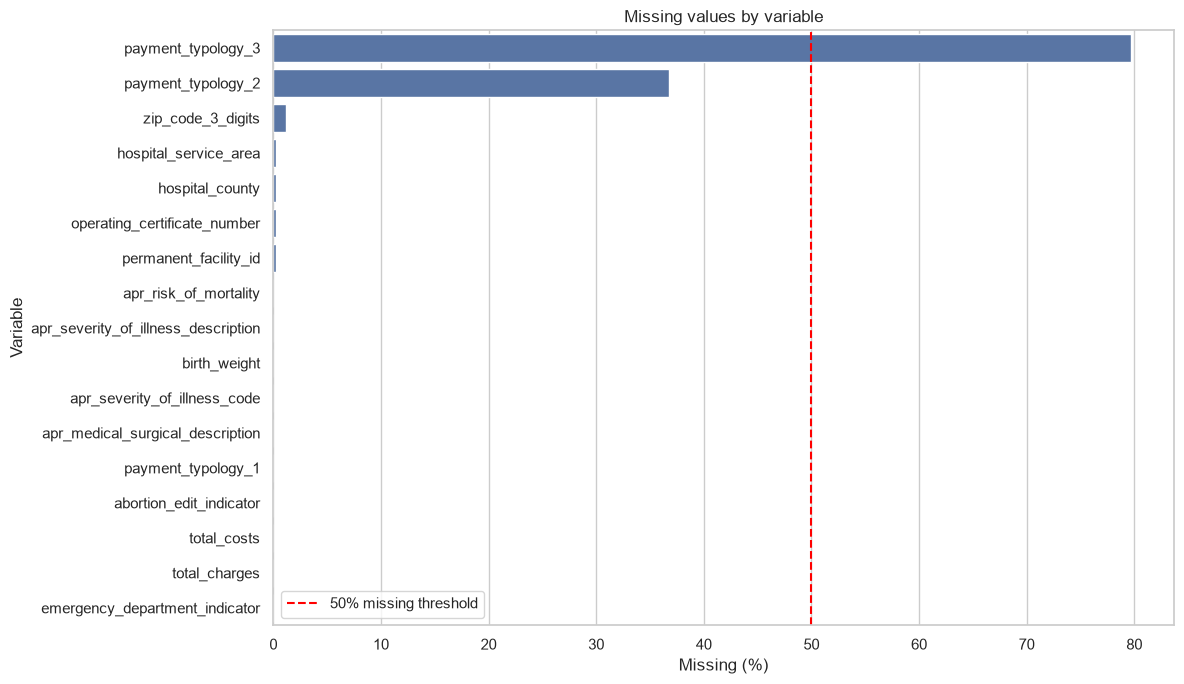


Dropping: ['payment_typology_2', 'payment_typology_3']


In [4]:
# 4. Missing values (50%)
missing_sum = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing perc': df.isnull().mean() * 100
}).sort_values('Missing perc', ascending=False)
display(missing_sum[missing_sum['Missing Values'] > 0])

miss_plot = missing_sum[missing_sum['Missing perc'] > 0].reset_index(names='var')
plt.figure(figsize=(12, 7))
sns.barplot(data=miss_plot, x='Missing perc', y='var')
plt.axvline(x=50, color='red', linestyle='--', label='50% missing threshold')
plt.title('Missing values by variable')
plt.xlabel('Missing (%)')
plt.ylabel('Variable')
plt.legend()
plt.tight_layout()
plt.show()

# Keep the information in payment_typology_2 as a simple flag before dropping it
df['has_secondary_payer'] = df['payment_typology_2'].notna().astype('int8')

drop_missing = missing_sum[missing_sum['Missing perc'] > 50].index.tolist()
drop_cols = sorted(set(drop_missing + ['payment_typology_2', 'payment_typology_3']))
print(f'\nDropping: {drop_cols}')
df = df.drop(columns=drop_cols)



#### Results: missing values

| Variable | Missing rows | Missing % | Decision |
|---|---:|---:|---|
| `payment_typology_3` | 280,222 | 79.70% | Dropped (above 50% threshold) |
| `payment_typology_2` | 129,119 | 36.72% | Dropped, but kept as the flag `has_secondary_payer` |
| `zip_code_3_digits` | 4,188 | 1.19% | Recoded to `Unknown` in section 3 |
| Service area, county, facility ID, certificate no. | 755 each | 0.21% | Same 755 rows (redacted facilities) |
| Severity, risk of mortality | 25 each | 0.01% | Imputed inside the model pipeline |
| 7 other columns | 1 each | ~0.00% | Negligible |

> **Takeaway:** missingness is concentrated in the optional secondary and tertiary payer fields. Converting the secondary payer into a yes/no flag keeps the useful signal (whether a second payer exists) without carrying 37% empty values.

In [5]:
# 5. Duplicates (reported, NOT removed: no patient identifier in SPARCS)
dup_n = df.duplicated().sum()
print(f'Exact duplicate rows: {dup_n:,} ({dup_n / len(df) * 100:.2f}%)')
display(df[df.duplicated(keep=False)].head(10))


Exact duplicate rows: 359 (0.10%)


,hospital_service_area,hospital_county,operating_certificate_number,permanent_facility_id,facility_name,age_group,zip_code_3_digits,gender,race,ethnicity,length_of_stay,type_of_admission,patient_disposition,discharge_year,ccs_diagnosis_code,ccs_diagnosis_description,ccs_procedure_code,ccs_procedure_description,apr_drg_code,apr_drg_description,apr_mdc_code,apr_mdc_description,apr_severity_of_illness_code,apr_severity_of_illness_description,apr_risk_of_mortality,apr_medical_surgical_description,payment_typology_1,birth_weight,abortion_edit_indicator,emergency_department_indicator,total_charges,total_costs,has_secondary_payer
1100,Western NY,Allegany,"228,000.00",39.00,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,0 to 17,148,M,White,Not Span/Hispanic,1,Newborn,Home or Self Care,2015,218,Liveborn,115,CIRCUMCISION,640,"Neonate birthwt >2499g, normal newborn or neon...",15,Newborns and Other Neonates with Conditions Or...,1.00,Minor,Minor,Medical,Medicaid,"3,200.00",N,N,"1,726.25",750.87,1
1209,Western NY,Allegany,"228,000.00",39.00,Memorial Hosp of Wm F & Gertrude F Jones A/K/A...,0 to 17,148,M,White,Not Span/Hispanic,1,Newborn,Home or Self Care,2015,218,Liveborn,115,CIRCUMCISION,640,"Neonate birthwt >2499g, normal newborn or neon...",15,Newborns and Other Neonates with Conditions Or...,1.00,Minor,Minor,Medical,Medicaid,"3,200.00",N,N,"1,726.25",750.87,1
8925,Western NY,Chautauqua,"601,000.00",98.00,Brooks Memorial Hospital,0 to 17,140,F,White,Spanish/Hispanic,2,Newborn,Home or Self Care,2015,218,Liveborn,0,NO PROC,640,"Neonate birthwt >2499g, normal newborn or neon...",15,Newborns and Other Neonates with Conditions Or...,1.00,Minor,Minor,Medical,Medicaid,"3,200.00",N,N,"3,768.10","4,714.76",0
8975,Western NY,Chautauqua,"601,000.00",98.00,Brooks Memorial Hospital,0 to 17,147,F,White,Not Span/Hispanic,2,Newborn,Home or Self Care,2015,218,Liveborn,0,NO PROC,640,"Neonate birthwt >2499g, normal newborn or neon...",15,Newborns and Other Neonates with Conditions Or...,1.00,Minor,Minor,Medical,Medicaid,"3,400.00",N,N,"3,795.10","4,725.29",0
9130,Western NY,Chautauqua,"601,000.00",98.00,Brooks Memorial Hospital,0 to 17,147,F,White,Not Span/Hispanic,2,Newborn,Home or Self Care,2015,218,Liveborn,0,NO PROC,640,"Neonate birthwt >2499g, normal newborn or neon...",15,Newborns and Other Neonates with Conditions Or...,1.00,Minor,Minor,Medical,Medicaid,"3,100.00",N,N,"3,795.10","4,725.29",0
9136,Western NY,Chautauqua,"601,000.00",98.00,Brooks Memorial Hospital,0 to 17,140,F,White,Spanish/Hispanic,2,Newborn,Home or Self Care,2015,218,Liveborn,0,NO PROC,640,"Neonate birthwt >2499g, normal newborn or neon...",15,Newborns and Other Neonates with Conditions Or...,1.00,Minor,Minor,Medical,Medicaid,"3,200.00",N,N,"3,768.10","4,714.76",0
9185,Western NY,Chautauqua,"601,000.00",98.00,Brooks Memorial Hospital,0 to 17,140,M,White,Not Span/Hispanic,2,Newborn,Home or Self Care,2015,218,Liveborn,0,NO PROC,640,"Neonate birthwt >2499g, normal newborn or neon...",15,Newborns and Other Neonates with Conditions Or...,1.00,Minor,Minor,Medical,Medicaid,"3,300.00",N,N,"3,795.10","4,725.29",0
9343,Western NY,Chautauqua,"601,000.00",98.00,Brooks Memorial Hospital,0 to 17,140,M,White,Not Span/Hispanic,2,Newborn,Home or Self Care,2015,218,Liveborn,0,NO PROC,640,"Neonate birthwt >2499g, normal newborn or neon...",15,Newborns and Other Neonates with Conditions Or...,1.00,Minor,Minor,Medical,Medicaid,"3,300.00",N,N,"3,795.10","4,725.29",0
9429,Western NY,Chautauqua,"601,000.00",98.00,Brooks Memorial Hospital,0 to 17,147,M,White,Not Span/Hispanic,1,Newborn,Home or Self Care,2015,218,Liveborn,115,CIRCUMCISION,640,"Neonate birthwt >2499g, normal newborn or neon...",15,Newborns and Other Neonates with Conditions Or...,1.00,Minor,Minor,Medical,Medicaid,"3,700.00",N,N,"2,275.60","2,523.46",0
9610,Western NY,Chautauqua,"601,000.00",98.00,Brooks Memorial Hospital,0 to 17,147,F,White,Not Span/Hispanic,2,Newborn,Home or Self Care,2015,218,Liveborn,0,NO PROC,640,"Neonate birthwt >24

#### Results: duplicate rows

- **359 exact duplicate rows (0.10%)** were found and **deliberately not removed**.
- SPARCS has no patient identifier, so identical rows cannot be told apart from different patients with the same attributes. The examples shown are mostly newborn records at small hospitals with 1 to 2 day stays, where identical rows are expected by chance.

> **Takeaway:** the duplicate rate is tiny and plausibly legitimate, so keeping the rows is the safer choice.

<a id="sec3"></a>
## 3. Data cleaning and feature engineering

Standardize labels, fix types, convert the LOS target, run consistency checks, and shrink memory use.

### Structural cleaning

In [6]:
# 6. Standardize text, placeholders, IDs, and drop uninformative columns
# 6a. Strip whitespace in all text columns
_, catcols = split_cols(df)
for c in catcols:
    df[c] = df[c].astype('string').str.strip()

# 6b. One consistent label for "unknown" placeholders
placeholder_cols = ['gender', 'race', 'ethnicity', 'type_of_admission',
                    'payment_typology_1', 'zip_code_3_digits']
for c in placeholder_cols:
    print(f'{c}: ', df[c].value_counts(dropna=False).head(8).to_dict())
    df[c] = df[c].replace({'Not Available': 'Unknown', 'U': 'Unknown'}).fillna('Unknown')

# 6c. Identifiers are categories, not numbers
df['permanent_facility_id'] = (df['permanent_facility_id'].astype('Int64')
                               .astype('string').fillna('Unknown'))
for c in ['operating_certificate_number']:
    df[c] = df[c].astype('Int64').astype('string').fillna('Unknown')
for c in ['ccs_diagnosis_code', 'ccs_procedure_code', 'apr_drg_code', 'apr_mdc_code']:
    df[c] = df[c].astype(str)

# 6d. Constant / near-constant / redundant columns
near_const = {c: df[c].value_counts(normalize=True, dropna=False).iloc[0]
              for c in df.columns}
print('\nColumns where one value covers >= 99.5% of rows:')
print({c: round(v, 4) for c, v in near_const.items() if v >= 0.995})
print('discharge_year levels:', df['discharge_year'].unique())

redundant = ['discharge_year',            # constant if only 2015
             'abortion_edit_indicator',   # near-constant, not relevant to LOS
             'operating_certificate_number']  # duplicates permanent_facility_id

miss_fac = df['hospital_service_area'].isna()
print(df.loc[miss_fac, 'facility_name'].value_counts().head(10))
print(pd.crosstab(miss_fac, df['abortion_edit_indicator']))
print(df.loc[miss_fac, 'length_of_stay'].describe())

# 111 rows?
miss_sev = df['apr_severity_of_illness_description'].isna()
print(df.loc[miss_sev, ['apr_drg_description', 'apr_medical_surgical_description']]
        .value_counts().head(10))

df = df.drop(columns=[c for c in redundant if c in df.columns])

# 6e. Birth weight: 0 means "not a newborn" -> flag + weight
df['is_newborn'] = (df['birth_weight'] > 0).astype('int8')
df['birth_weight_g'] = df['birth_weight'].where(df['birth_weight'] > 0, 0).astype('float32')
df = df.drop(columns='birth_weight')
print(f'\nNewborn records: {df["is_newborn"].mean() * 100:.2f}%')

# 6f. Binary and ordinal encodings
df['emergency_department_flag'] = (df['emergency_department_indicator']
                                   .map({'Y': 1, 'N': 0}).astype('float32'))
age_order = {'0 to 17': 0, '18 to 29': 1, '30 to 49': 2, '50 to 69': 3, '70 or Older': 4}
df['age_group_ord'] = df['age_group'].map(age_order).astype('float32')
print('Unmapped age groups:', df['age_group_ord'].isna().sum())
print('Unmapped ED flags:', df['emergency_department_flag'].isna().sum())


gender:  {'F': 199449, 'M': 152134, 'U': 3}
race:  {'White': 282877, 'Black/African American': 42279, 'Other Race': 24510, 'Multi-racial': 1920}
ethnicity:  {'Not Span/Hispanic': 331910, 'Spanish/Hispanic': 11557, 'Unknown': 6977, 'Multi-ethnic': 1142}
type_of_admission:  {'Emergency': 198013, 'Elective': 84705, 'Urgent': 36159, 'Newborn': 32601, 'Not Available': 106, 'Trauma': 2}
payment_typology_1:  {'Medicare': 149261, 'Medicaid': 82956, 'Blue Cross/Blue Shield': 55419, 'Private Health Insurance': 39435, 'Self-Pay': 10469, 'Miscellaneous/Other': 6784, 'Managed Care, Unspecified': 3750, 'Federal/State/Local/VA': 2747}
zip_code_3_digits:  {'142': 65718, '146': 55663, '140': 43409, '145': 30826, '144': 28773, '141': 20845, '148': 18855, '147': 17152}

Columns where one value covers >= 99.5% of rows:
{'discharge_year': np.float64(1.0), 'abortion_edit_indicator': np.float64(0.9992)}
discharge_year levels: [2015]
facility_name
Redacted for Confidentiality    755
Name: count, dtype: Int64


#### Results: standardization and structural cleaning

| Check | Finding | Action |
|---|---|---|
| Unknown placeholders | Gender `U` (3 rows), admission type `Not Available` (106 rows), plus missing zip / payer values | Recoded to a single `Unknown` label |
| Constant columns | `discharge_year` is 2015 in 100% of rows; `abortion_edit_indicator` is `N` in 99.92% | Dropped |
| Redundant ID | `operating_certificate_number` duplicates `permanent_facility_id` | Dropped |
| Redacted facilities | 755 rows carry the facility name *Redacted for Confidentiality* and no service area or county. All 265 `abortion_edit_indicator = Y` rows are in this group, and 277 of the 755 are 1-day stays | Kept, facility ID set to `Unknown` |
| Missing severity | 25 rows; 24 of them have an invalid principal diagnosis (20) or an ungroupable DRG (4) | Kept |
| Newborn flag | `birth_weight > 0` marks **9.71%** of records as newborns | Created `is_newborn` and `birth_weight_g` |
| Encodings | Age groups mapped to 0 to 4 with no gaps; one record has no ED indicator | Created `age_group_ord`, `emergency_department_flag` |

> **Takeaway:** the redacted-facility rows are a small, distinctive group (0.21% of data) that cannot be linked to a hospital. They are retained but will behave as an "unknown facility" category.

In [7]:
# 7. Clean LOS ("120 +" = 120 or more days: keep it and flag as censored)
print(df['length_of_stay'].value_counts().head(10))
los_raw = df['length_of_stay'].astype('string').str.strip()
df['los_censored'] = los_raw.str.contains(r'\+', na=False)
df['length_of_stay'] = pd.to_numeric(
    los_raw.str.replace(r'\s*\+', '', regex=True), errors='coerce')

print('Top-coded (120+) stays:', df['los_censored'].sum())
print('Missing/unparseable LOS:', df['length_of_stay'].isna().sum())
print('LOS < 1:', (df['length_of_stay'] < 1).sum())

df = df.dropna(subset=['length_of_stay'])
df = df[df['length_of_stay'] >= 1].copy()

# Outliers are kept (real long stays matter for bed-days). Provide model-friendly versions.
df['los_log'] = np.log1p(df['length_of_stay'])
cap99 = df['length_of_stay'].quantile(0.995)
df['los_capped'] = df['length_of_stay'].clip(upper=cap99)
print(f'LOS cap (99.5th percentile): {cap99:.0f} days')

los = df['length_of_stay']



length_of_stay
2     83038
3     65054
1     52275
4     36545
5     24142
6     17933
7     13836
8      9794
9      7091
10     5524
Name: count, dtype: Int64
Top-coded (120+) stays: 295
Missing/unparseable LOS: 0
LOS < 1: 0
LOS cap (99.5th percentile): 51 days


#### Results: target cleaning (length of stay)

| Item | Value |
|---|---|
| Most common stays | 2 days (83,038), 3 days (65,054), 1 day (52,275) |
| Top-coded stays (`120 +`) | **295** (0.084%), kept and flagged in `los_censored` |
| Missing or unparseable LOS | 0 |
| LOS below 1 day | 0 |
| Winsorization cap (99.5th percentile) | **51 days**, stored in `los_capped` |

Derived targets available for modeling: `length_of_stay` (days), `los_log` (log of 1 + LOS) and `los_capped`.

> **Takeaway:** no rows were lost. Top-coded stays are *lower bounds* on true LOS, so bed-day totals computed from them are conservative.

In [8]:
# 8. Data-quality consistency checks
print('Charges <= 0:', (df['total_charges'] <= 0).sum())
print('Costs <= 0:', (df['total_costs'] <= 0).sum())
print('Costs > charges: '
      f'{(df["total_costs"] > df["total_charges"]).mean() * 100:.2f}%')
print('\nNewborn flag by age group:')
display(pd.crosstab(df['age_group'], df['is_newborn']))
print('Newborn flag by admission type:')
display(pd.crosstab(df['type_of_admission'], df['is_newborn']))



Charges <= 0: 0
Costs <= 0: 0
Costs > charges: 1.06%

Newborn flag by age group:


is_newborn,0,1
age_group,,
0 to 17,13519,34122
18 to 29,37531,0
30 to 49,58950,0
50 to 69,101173,0
70 or Older,106291,0


Newborn flag by admission type:


is_newborn,0,1
type_of_admission,,
Elective,84566,139
Emergency,197516,497
Newborn,5,32596
Trauma,1,1
Unknown,106,0
Urgent,35270,889


#### Results: consistency checks

- **Charges and costs:** none are zero or negative. Costs exceed charges in **1.06%** of rows, which is unusual and worth keeping in mind but not large enough to affect LOS modeling.
- **Newborn flag vs. age:** every record outside the 0 to 17 age group has `is_newborn = 0`. Within 0 to 17, 34,122 are newborns and 13,519 are not.
- **Newborn flag vs. admission type:** the two definitions overlap but are not identical.

| | `is_newborn = 0` | `is_newborn = 1` |
|---|---:|---:|
| Admission type *Newborn* | 5 | 32,596 |
| Elective / Emergency / Urgent / Trauma | 84,566 / 197,516 / 35,270 / 1 | 139 / 497 / 889 / 1 |
| Unknown admission type | 106 | 0 |

> **Takeaway:** 1,526 records with a birth weight were not admitted as "Newborn". This matters later because `type_of_admission` is an admission-time feature while `is_newborn` (derived from birth weight) is excluded from the admission model.

In [9]:
# 9. Memory: convert text columns to category
for c in df.select_dtypes(include=['string', 'object']).columns:
    df[c] = df[c].astype('category')
print(f'Memory after conversion: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB')


Memory after conversion: 34 MB


#### Results: memory optimization

Converting text columns to the `category` dtype reduces the frame to roughly **34 MB** (the raw frame was about 91 MB), which makes the later one-hot encoding and model fitting practical.

<a id="sec4"></a>
## 4. Target variable: length of stay


### Target variable: length of stay


In [10]:
# 10. LOS summary and outliers
q1, q3 = los.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print(f'Mean {los.mean():.2f} | Median {los.median():.2f} | Std {los.std():.2f} '
      f'| Min {los.min()} | Max {los.max()}')
print(f'Skewness: {los.skew():.2f} | Kurtosis: {los.kurt():.2f}')
print(f'IQR upper fence: {upper_fence:.1f} days | stays above fence: '
      f'{(los > upper_fence).mean() * 100:.2f}%')
print(f'Stays > 30 days: {(los > 30).mean() * 100:.2f}%')
print(f'Censored at 120+: {df["los_censored"].mean() * 100:.3f}%')
display(los.quantile([.5, .75, .9, .95, .99, .999]).to_frame('LOS percentile'))


Mean 5.31 | Median 3.00 | Std 7.91 | Min 1 | Max 120
Skewness: 6.79 | Kurtosis: 70.39
IQR upper fence: 12.0 days | stays above fence: 8.02%
Stays > 30 days: 1.43%
Censored at 120+: 0.084%


,LOS percentile
0.50,3.00
0.75,6.00
0.90,11.00
0.95,16.00
0.99,37.00
1.00,111.00


#### Results: LOS summary statistics

| Statistic | Value | | Percentile | LOS (days) |
|---|---:|---|---|---:|
| Mean | 5.31 | | 50th | 3 |
| Median | 3.00 | | 75th | 6 |
| Std. deviation | 7.91 | | 90th | 11 |
| Min / Max | 1 / 120 | | 95th | 16 |
| Skewness | 6.79 | | 99th | 37 |
| Kurtosis | 70.39 | | 99.9th | 111 |

- IQR upper fence is **12 days**; **8.02%** of stays lie above it.
- **1.43%** of stays exceed 30 days; **0.084%** are top-coded at 120+.

> **Takeaway:** the mean (5.3) is well above the median (3), and the standard deviation (7.9) exceeds the mean. A small number of very long stays drive the variance, which is why error metrics will be dominated by the tail.

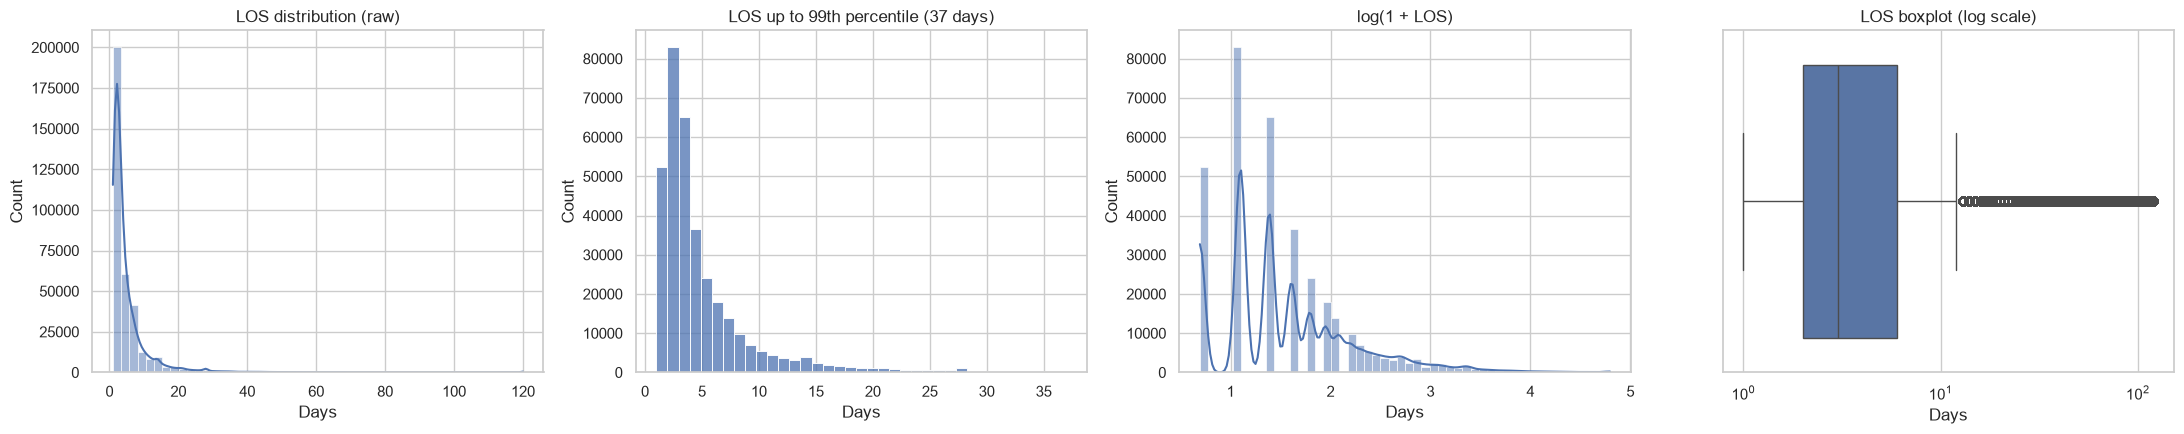

In [11]:
# 11. LOS distribution (raw, capped, log)
cap = los.quantile(0.99)
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
sns.histplot(los, bins=50, kde=True, ax=axes[0])
axes[0].set_title('LOS distribution (raw)')
sns.histplot(los[los <= cap], bins=int(cap), ax=axes[1])
axes[1].set_title(f'LOS up to 99th percentile ({cap:.0f} days)')
sns.histplot(df['los_log'], bins=50, kde=True, ax=axes[2])
axes[2].set_title('log(1 + LOS)')
sns.boxplot(x=los, ax=axes[3])
axes[3].set_xscale('log')
axes[3].set_title('LOS boxplot (log scale)')
for ax in axes:
    ax.set_xlabel('Days')
plt.tight_layout()
plt.show()


#### Results: LOS distribution

The four panels show the raw distribution, the distribution truncated at the 99th percentile (37 days), the log-transformed target, and a log-scale boxplot.

- The raw histogram is a tall spike at 1 to 3 days with a very long right tail.
- The log transform compresses that tail, which is why log-scale targets and Poisson-type losses are tried in section 7.
- The boxplot shows many "outliers" beyond the 12-day fence. They are **kept**, since long stays consume a disproportionate share of bed-days.

<a id="sec5"></a>
## 5. Exploratory analysis of predictors

Inspect category cardinality, compare LOS across key groups, identify the service lines and hospitals that consume the most bed-days, and check numeric correlations.


### Predictor review


In [12]:
# 12. Cardinality (encoding planning) and distributions
cat_cols = df.select_dtypes(include=['category']).columns.tolist()
card = pd.DataFrame({
    'n_unique': df[cat_cols].nunique(),
    'top_level_share_%': [df[c].value_counts(normalize=True).iloc[0] * 100 for c in cat_cols]
}).sort_values('n_unique')
display(card)

key_cats = ['age_group', 'gender', 'race', 'ethnicity', 'type_of_admission',
            'emergency_department_indicator', 'payment_typology_1',
            'apr_medical_surgical_description']
for c in key_cats:
    print(f'\n{c}')
    display(pd.concat([df[c].value_counts(dropna=False).head(15).rename('n'),
                       (df[c].value_counts(normalize=True, dropna=False).head(15) * 100)
                       .rename('%')], axis=1))



,n_unique,top_level_share_%
emergency_department_indicator,2,55.90
gender,3,56.73
apr_medical_surgical_description,3,74.23
race,4,80.46
apr_risk_of_mortality,4,55.07
apr_severity_of_illness_description,4,38.04
ethnicity,4,94.40
hospital_service_area,5,46.70
age_group,5,30.23
type_of_admission,6,56.32



age_group


,n,%
age_group,,
70 or Older,106291,30.23
50 to 69,101173,28.78
30 to 49,58950,16.77
0 to 17,47641,13.55
18 to 29,37531,10.67



gender


,n,%
gender,,
F,199449,56.73
M,152134,43.27
Unknown,3,0.00



race


... (7 outputs left out)


payment_typology_1


,n,%
payment_typology_1,,
Medicare,149261,42.45
Medicaid,82956,23.59
Blue Cross/Blue Shield,55419,15.76
Private Health Insurance,39435,11.22
Self-Pay,10469,2.98
Miscellaneous/Other,6784,1.93
"Managed Care, Unspecified",3750,1.07
Federal/State/Local/VA,2747,0.78
Department of Corrections,651,0.19



apr_medical_surgical_description


,n,%
apr_medical_surgical_description,,
Medical,260980,74.23
Surgical,90581,25.76
Not Applicable,24,0.01
<NA>,1,0.00


#### Results: cardinality and category distributions

**Cardinality (encoding planning).** Most predictors are low-cardinality (2 to 10 levels). High-cardinality fields are the clinical codes (316 DRGs, 262 CCS diagnoses, 227 CCS procedures), 59 facility names and 44 zip prefixes.

| Variable | Largest levels |
|---|---|
| Age group | 70 or older 30.2%, 50 to 69 28.8%, 30 to 49 16.8%, 0 to 17 13.6%, 18 to 29 10.7% |
| Gender | Female 56.7%, Male 43.3% |
| Race | White 80.5%, Black/African American 12.0%, Other 7.0%, Multi-racial 0.6% |
| Ethnicity | Not Spanish/Hispanic 94.4%, Spanish/Hispanic 3.3% |
| Admission type | Emergency 56.3%, Elective 24.1%, Urgent 10.3%, Newborn 9.3% |
| ED indicator | Yes 55.9%, No 44.1% |
| Primary payer | Medicare 42.5%, Medicaid 23.6%, Blue Cross/Blue Shield 15.8%, Private 11.2% |
| Medical / surgical | Medical 74.2%, Surgical 25.8% |

> **Takeaway:** the population skews older and toward emergency admissions with Medicare coverage. Several groups (multi-racial, trauma, unknown admission type) are very small, so group-level comparisons for them are unreliable.


LOS by type_of_admission


,count,mean,median,std
type_of_admission,,,,
Emergency,198013,5.69,4.00,7.83
Elective,84705,4.46,3.00,6.48
Urgent,36159,6.68,3.00,10.01
Unknown,106,6.36,3.00,11.45
Trauma,2,2.50,2.50,0.71
Newborn,32601,3.69,2.00,8.63


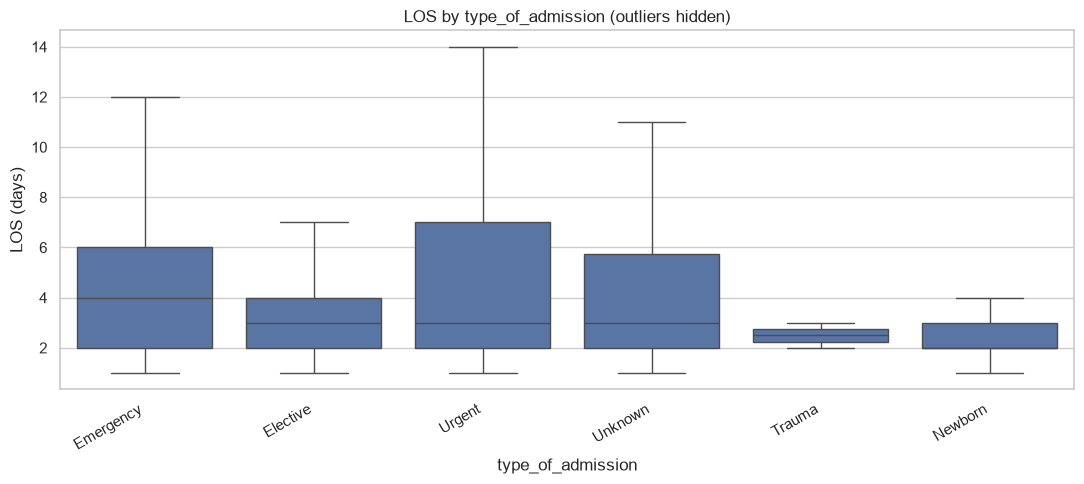


LOS by age_group


,count,mean,median,std
age_group,,,,
70 or Older,106291,5.91,4.00,7.44
50 to 69,101173,5.93,3.00,8.70
30 to 49,58950,4.79,3.00,7.11
18 to 29,37531,4.28,3.00,6.33
0 to 17,47641,4.11,2.00,8.91


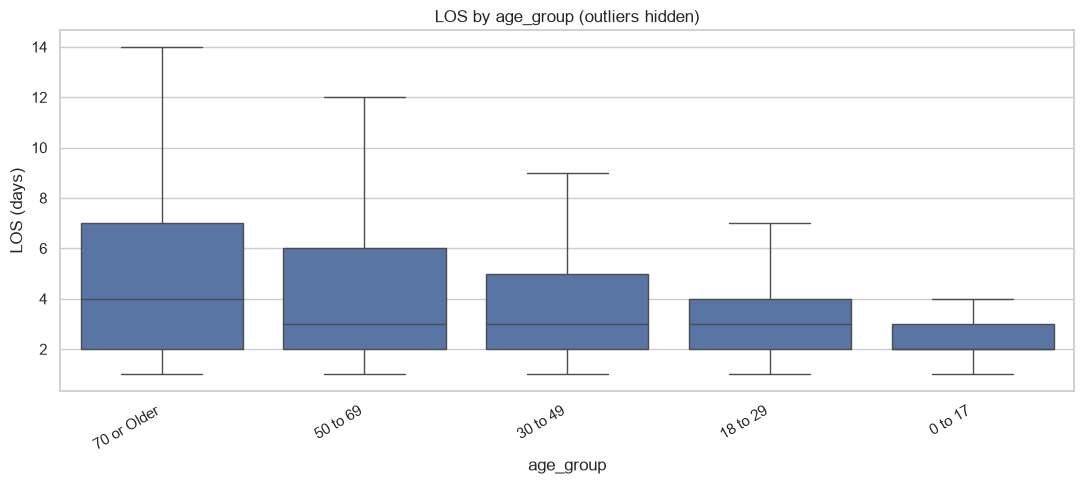


LOS by emergency_department_indicator


,count,mean,median,std
emergency_department_indicator,,,,
Y,196525,5.66,4.00,7.78
N,155060,4.86,3.00,8.05


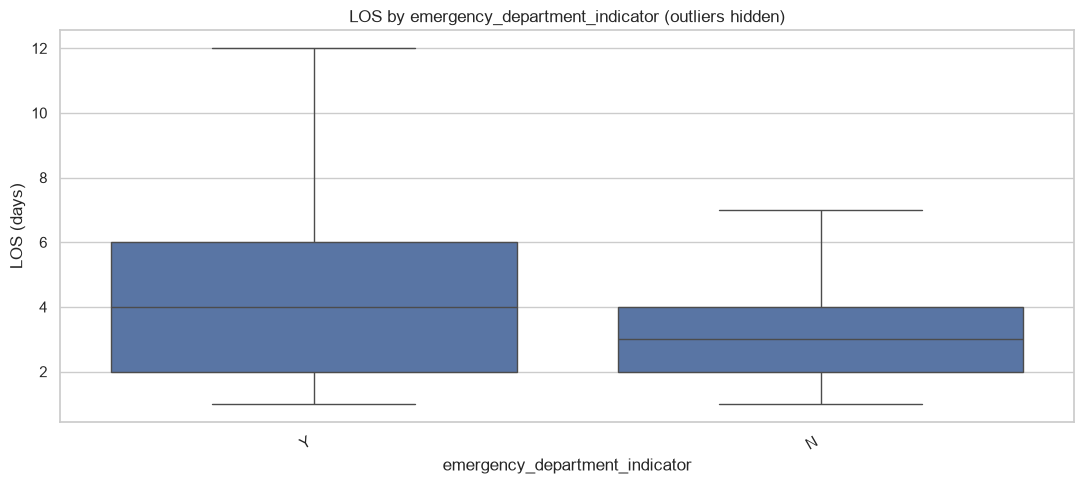


LOS by payment_typology_1


,count,mean,median,std
payment_typology_1,,,,
Medicare,149261,6.15,4.00,8.16
Department of Corrections,651,5.94,4.00,8.11
Unknown,114,5.84,4.00,6.07
Medicaid,82956,5.27,3.00,8.92
Blue Cross/Blue Shield,55419,4.04,3.00,6.30
Private Health Insurance,39435,4.29,3.00,6.69
Miscellaneous/Other,6784,4.75,3.00,7.39
Self-Pay,10469,4.49,3.00,6.85
Federal/State/Local/VA,2747,4.79,3.00,7.20


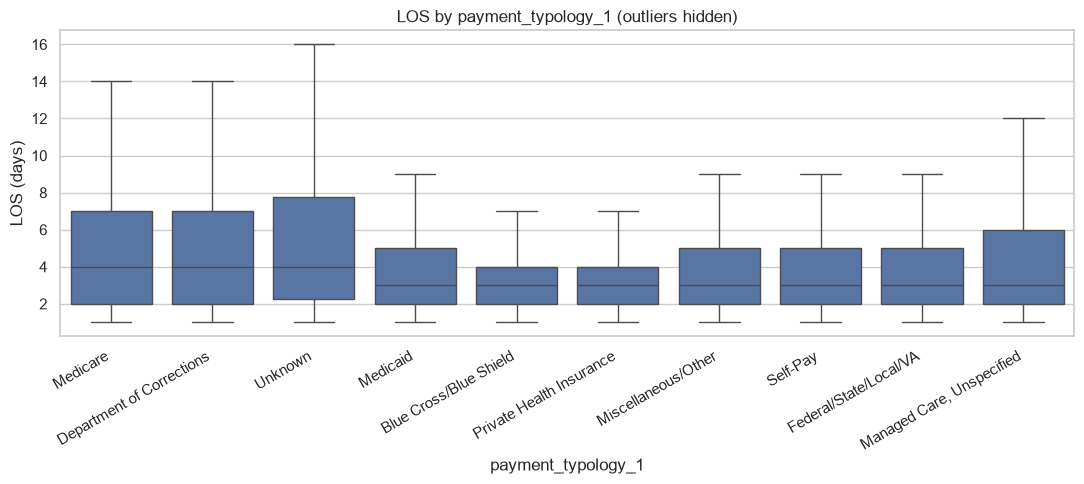


LOS by gender


,count,mean,median,std
gender,,,,
F,199449,4.91,3.00,7.18
M,152134,5.83,3.00,8.75
Unknown,3,1.67,2.00,0.58


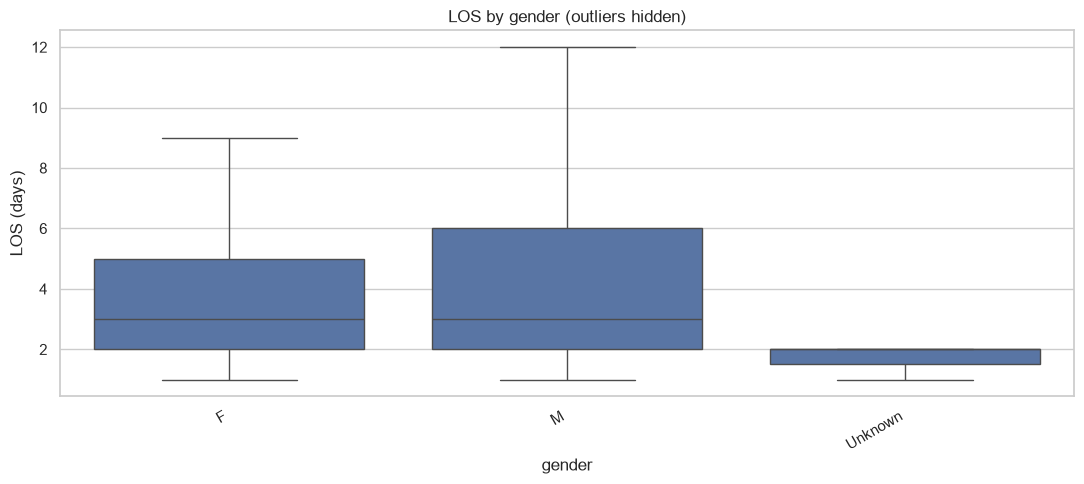


LOS by race


,count,mean,median,std
race,,,,
White,282877,5.26,3.00,7.61
Black/African American,42279,5.98,3.00,9.69
Other Race,24510,4.81,3.00,7.99
Multi-racial,1920,4.29,3.00,6.07


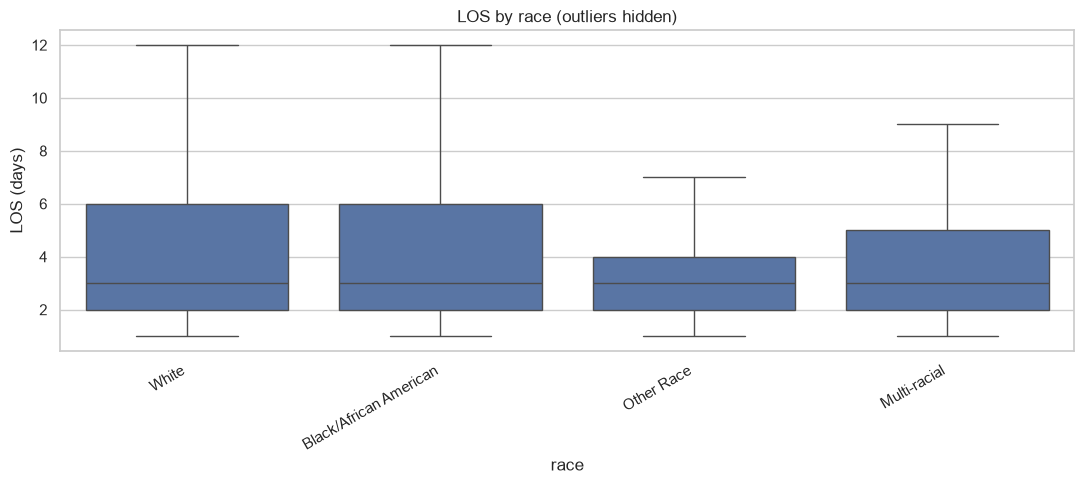


LOS by ethnicity


,count,mean,median,std
ethnicity,,,,
Multi-ethnic,1142,5.05,4.00,5.11
Not Span/Hispanic,331910,5.35,3.00,7.96
Spanish/Hispanic,11557,4.62,3.00,7.43
Unknown,6977,4.39,3.00,6.22


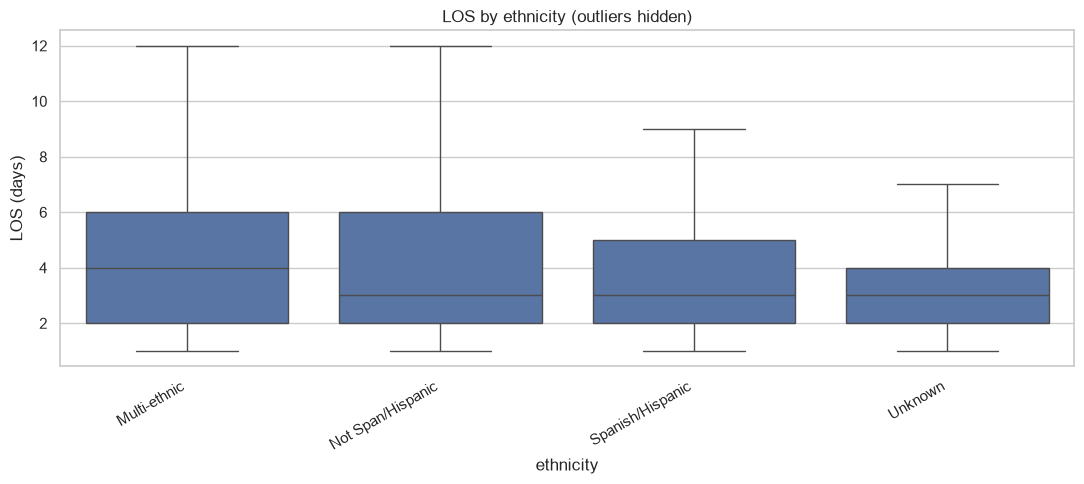

In [13]:
# 13. LOS by key admission-time predictors
def los_by(col, top_n=15, order_by='median', rotate=30, figsize=(11, 5)):
    g = (df.groupby(col, observed=True)['length_of_stay']
           .agg(['count', 'mean', 'median', 'std'])
           .sort_values('count', ascending=False).head(top_n)
           .sort_values(order_by, ascending=False))
    print(f'\nLOS by {col}')
    display(g)
    plt.figure(figsize=figsize)
    sns.boxplot(data=df[df[col].isin(g.index)], x=col, y='length_of_stay',
                order=g.index.tolist(), showfliers=False)
    plt.title(f'LOS by {col} (outliers hidden)')
    plt.xlabel(col)
    plt.ylabel('LOS (days)')
    plt.xticks(rotation=rotate, ha='right')
    plt.tight_layout()
    plt.show()

for c in ['type_of_admission', 'age_group', 'emergency_department_indicator',
          'payment_typology_1', 'gender', 'race', 'ethnicity']:
    los_by(c)

#### Results: LOS by admission-time predictors

| Predictor | Longest stays (mean LOS, days) | Shortest stays |
|---|---|---|
| Admission type | Urgent **6.68**, Emergency 5.69 | Newborn 3.69, Elective 4.46 |
| Age group | 50 to 69 **5.93**, 70 or older 5.91 | 0 to 17: 4.11 |
| ED indicator | ED admission 5.66 | Non-ED 4.86 |
| Primary payer | Medicare **6.15**, Managed care 5.66, Medicaid 5.27 | Blue Cross/Blue Shield 4.04, Private 4.29 |
| Gender | Male 5.83 | Female 4.91 |
| Race | Black/African American 5.98 | Multi-racial 4.29, Other 4.81 |
| Ethnicity | Not Spanish/Hispanic 5.35 | Spanish/Hispanic 4.62 |

**Reading the table**

- **Medians are almost flat** (mostly 3 days; 4 for Medicare, emergency and ED admissions). The differences in means come largely from the long tail.
- Standard deviations (6 to 10 days) are larger than the gaps between groups, so the groups overlap heavily and no single field separates short from long stays.
- These are descriptive, unadjusted differences. Case mix, age and hospital type are confounded with payer, gender and race, so they should not be read as causal effects.

> **Takeaway:** admission type, age, payer and ED status carry some signal, but only modest, which anticipates the low R² of admission-time models.


Service category: apr_mdc_description  (n categories = 26)


,discharges,mean_los,median_los,bed_days,share_of_bed_days_%,share_of_discharges_%
apr_mdc_description,,,,,,
Diseases and Disorders of the Circulatory System,41628,5.13,3.00,213393,11.43,11.84
"Infectious and Parasitic Diseases, Systemic or Unspecified Sites",22616,8.14,5.00,184167,9.87,6.43
Diseases and Disorders of the Respiratory System,32270,5.32,4.00,171791,9.20,9.18
Diseases and Disorders of the Musculoskeletal System and Conn Tissue,38957,4.13,3.00,161062,8.63,11.08
Mental Diseases and Disorders,17023,9.39,6.00,159901,8.57,4.84
Diseases and Disorders of the Digestive System,30006,5.19,4.00,155627,8.34,8.53
Newborns and Other Neonates with Conditions Originating in the Perinatal Period,33668,3.91,2.00,131607,7.05,9.58
Diseases and Disorders of the Nervous System,20952,5.72,3.00,119810,6.42,5.96
"Pregnancy, Childbirth and the Puerperium",35199,2.69,2.00,94523,5.06,10.01


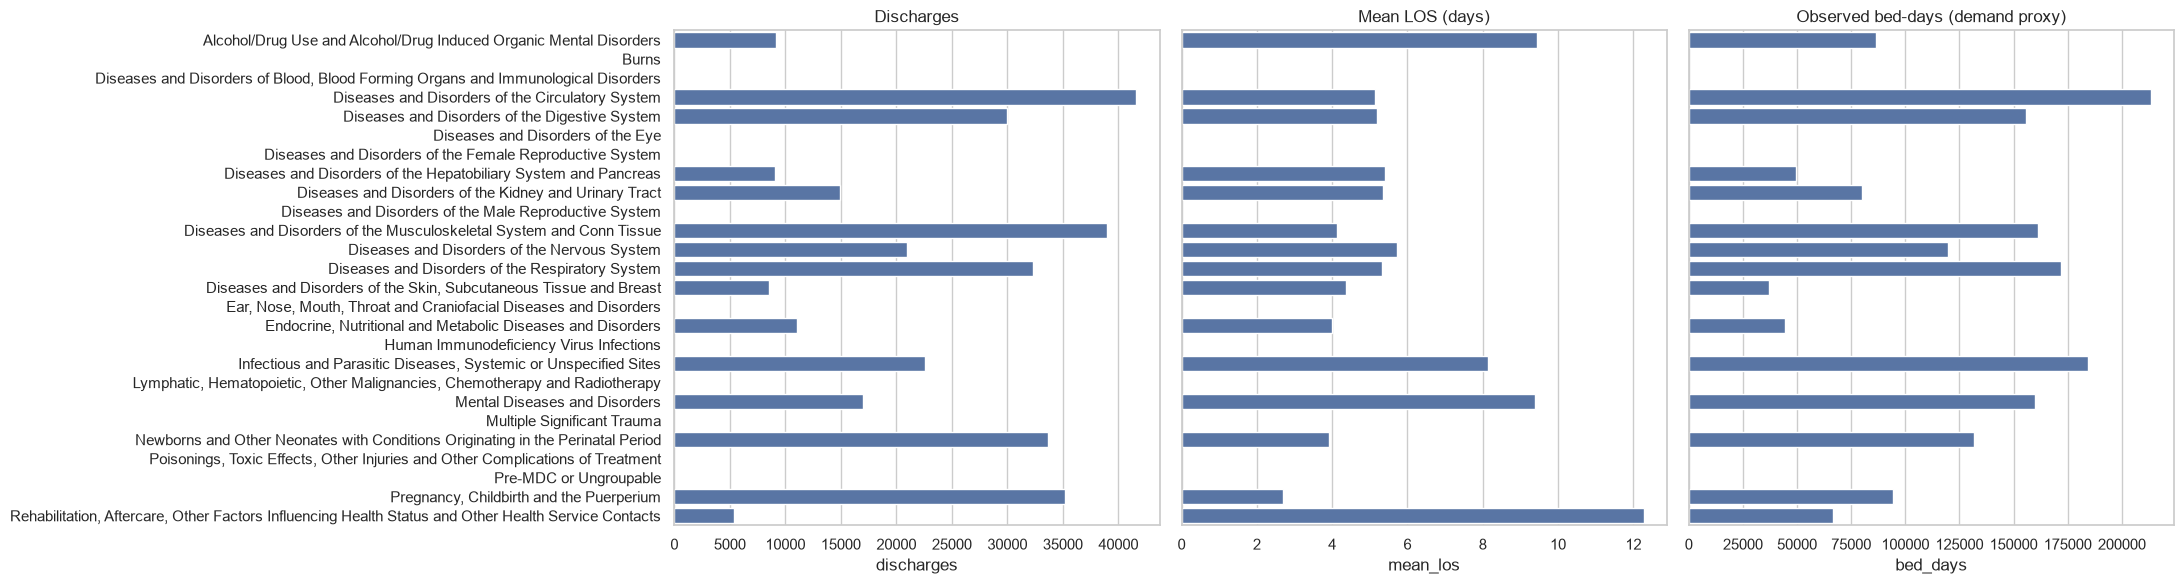


Service category: apr_medical_surgical_description  (n categories = 3)


,discharges,mean_los,median_los,bed_days,share_of_bed_days_%,share_of_discharges_%
apr_medical_surgical_description,,,,,,
Medical,260980,5.11,3.00,1333222,71.42,74.23
Surgical,90581,5.89,3.00,533469,28.58,25.76
Not Applicable,24,2.42,2.00,58,0.00,0.01


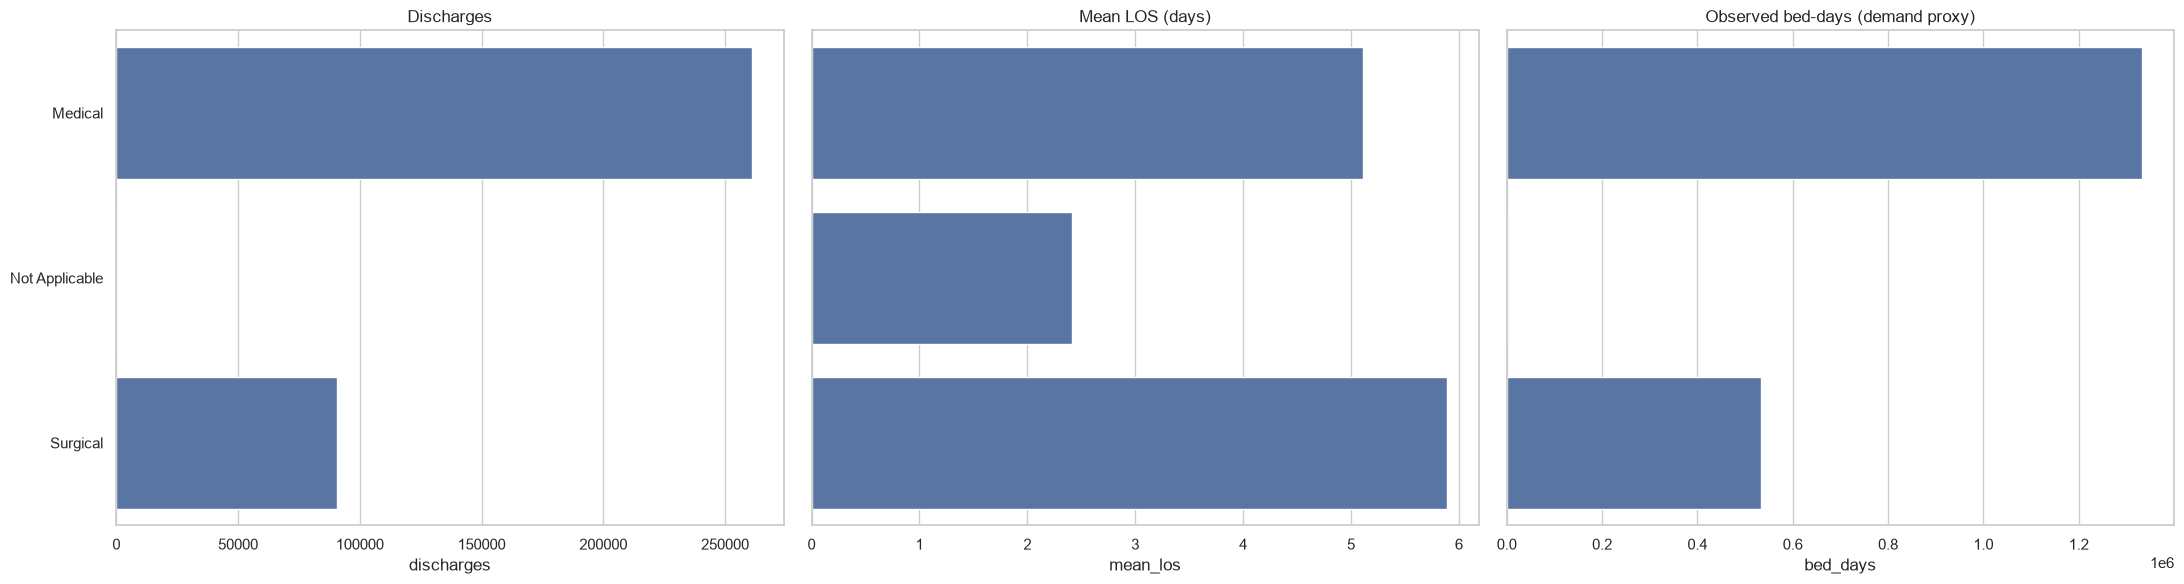

In [14]:
# 14. Clinical service categories (basis for the LP model)
for col in ['apr_mdc_description', 'apr_medical_surgical_description']:
    svc = (df.groupby(col, observed=True)['length_of_stay']
             .agg(discharges='count', mean_los='mean', median_los='median',
                  bed_days='sum')
             .sort_values('bed_days', ascending=False))
    svc['share_of_bed_days_%'] = svc['bed_days'] / svc['bed_days'].sum() * 100
    svc['share_of_discharges_%'] = svc['discharges'] / svc['discharges'].sum() * 100
    print(f'\nService category: {col}  (n categories = {len(svc)})')
    display(svc.head(25))

    top = svc.head(15).reset_index()
    fig, axes = plt.subplots(1, 3, figsize=(22, 6), sharey=True)
    sns.barplot(data=top, x='discharges', y=col, ax=axes[0])
    axes[0].set_title('Discharges')
    sns.barplot(data=top, x='mean_los', y=col, ax=axes[1])
    axes[1].set_title('Mean LOS (days)')
    sns.barplot(data=top, x='bed_days', y=col, ax=axes[2])
    axes[2].set_title('Observed bed-days (demand proxy)')
    for ax in axes:
        ax.set_ylabel('')
    plt.tight_layout()
    plt.show()

#### Results: clinical service categories (basis for bed-day planning)

**Top service lines by observed bed-days (APR MDC, 26 categories)**

| Service line | Discharges | Mean LOS | Median LOS | Bed-days | Share of bed-days |
|---|---:|---:|---:|---:|---:|
| Circulatory system | 41,628 | 5.13 | 3 | 213,393 | 11.43% |
| Infectious / parasitic (systemic) | 22,616 | 8.14 | 5 | 184,167 | 9.87% |
| Respiratory system | 32,270 | 5.32 | 4 | 171,791 | 9.20% |
| Musculoskeletal system | 38,957 | 4.13 | 3 | 161,062 | 8.63% |
| Mental diseases and disorders | 17,023 | 9.39 | 6 | 159,901 | 8.57% |
| Digestive system | 30,006 | 5.19 | 4 | 155,627 | 8.34% |

**Longest average stays:** Rehabilitation/aftercare (12.27 days, median 9), Lymphatic/hematopoietic malignancies (9.79), Multiple significant trauma (9.63), Alcohol/drug use (9.44), Mental disorders (9.39), HIV (9.21).
**Shortest:** Pregnancy/childbirth (2.69), Male reproductive (3.01), Female reproductive (3.11).

**Medical vs. surgical:** medical cases are 74.23% of discharges and 71.42% of bed-days (mean LOS 5.11); surgical cases are 25.76% of discharges but 28.58% of bed-days (mean LOS 5.89).

> **Takeaway:** volume and bed-day burden are not the same ranking. Mental health has only 17,023 discharges but is the 5th-largest consumer of bed-days because of its 9.4-day average stay. This is why service-line LOS accuracy matters for capacity planning.

Total Hospitals: 59


,count,mean,median
facility_name,,,
Strong Memorial Hospital,38653,7.08,4.00
Rochester General Hospital,29798,5.27,3.00
Buffalo General Medical Center,22872,5.82,3.00
Highland Hospital,18778,4.17,3.00
The Unity Hospital of Rochester,17223,5.17,3.00
Millard Fillmore Suburban Hospital,16743,4.05,3.00
Erie County Medical Center,16237,7.75,4.00
Mercy Hospital of Buffalo,15301,4.90,3.00
Sisters of Charity Hospital,14130,4.58,3.00


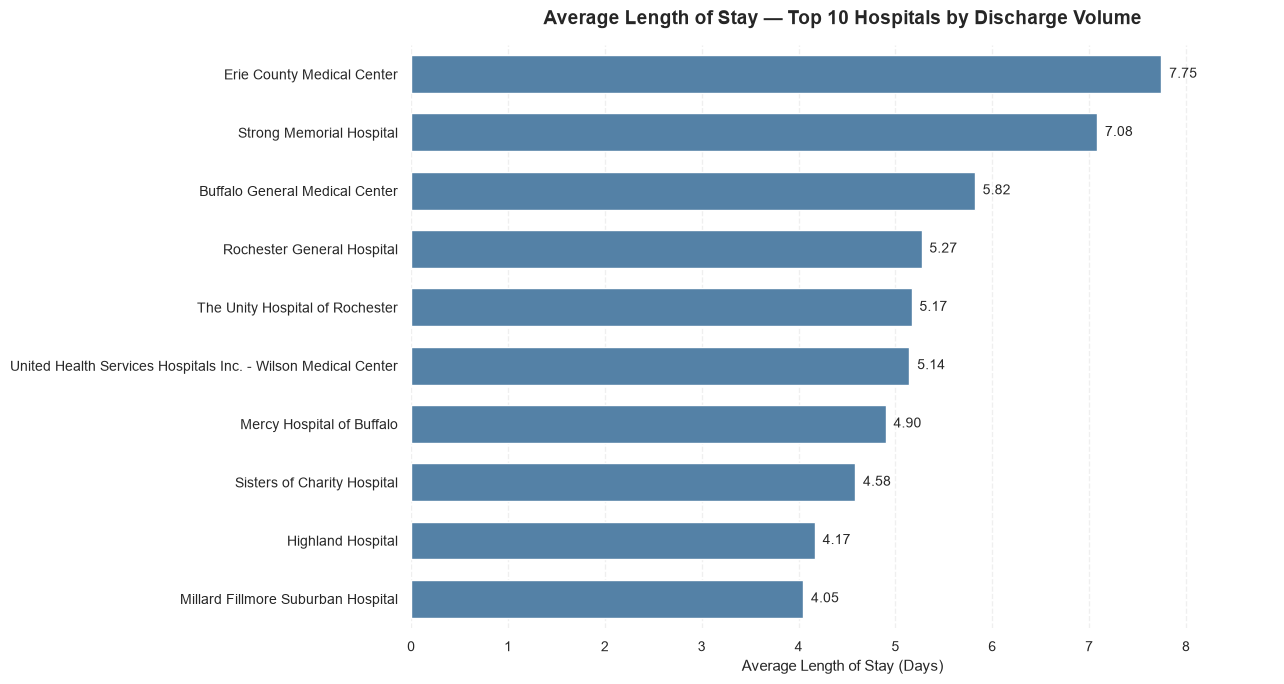

In [15]:
# 15. Hospital-Level Variation
# Average LOS for the Top 10 Hospitals by Discharge Volume

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate hospital-level statistics
hosp = (
    df.groupby('facility_name', observed=True)['length_of_stay']
    .agg(['count', 'mean', 'median'])
    .sort_values('count', ascending=False)
)

print(f'Total Hospitals: {len(hosp)}')
display(hosp.head(15))

# Select top 10 hospitals based on discharge volume
top10 = (
    hosp.head(10)
    .sort_values('mean', ascending=False)
    .reset_index()
    .copy()
)

# Convert hospital names to strings to avoid unused category labels
top10['facility_name'] = top10['facility_name'].astype(str)

# Create plot
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(13, 7))

sns.barplot(
    data=top10,
    x='mean',
    y='facility_name',
    order=top10['facility_name'].tolist(),
    color='steelblue',
    width=0.65,
    errorbar=None,
    ax=ax
)

# Add LOS values at the end of each bar
for bar in ax.patches:
    width = bar.get_width()

    ax.text(
        width + 0.08,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.2f}',
        va='center',
        fontsize=10
    )

# Formatting
ax.set_title(
    'Average Length of Stay — Top 10 Hospitals by Discharge Volume',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Average Length of Stay (Days)', fontsize=11)
ax.set_ylabel('')

ax.set_xlim(0, top10['mean'].max() * 1.15)

ax.tick_params(axis='y', labelsize=10)
ax.tick_params(axis='x', labelsize=10)

# Clean appearance
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.grid(axis='y', visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

#### Results: hospital-level variation

There are 59 facility names. The ten highest-volume hospitals differ considerably in average LOS:

| Hospital | Discharges | Mean LOS | Median |
|---|---:|---:|---:|
| Strong Memorial Hospital | 38,653 | **7.08** | 4 |
| Rochester General Hospital | 29,798 | 5.27 | 3 |
| Buffalo General Medical Center | 22,872 | 5.82 | 3 |
| Highland Hospital | 18,778 | 4.17 | 3 |
| The Unity Hospital of Rochester | 17,223 | 5.17 | 3 |
| Millard Fillmore Suburban Hospital | 16,743 | **4.05** | 3 |
| Erie County Medical Center | 16,237 | **7.75** | 4 |
| Mercy Hospital of Buffalo | 15,301 | 4.90 | 3 |
| Sisters of Charity Hospital | 14,130 | 4.58 | 3 |
| United Health Services (Wilson) | 13,318 | 5.14 | 3 |

- Mean LOS ranges from about **4.1 to 7.8 days** among these ten hospitals, almost a 2x spread.
- Erie County Medical Center and Strong Memorial are the longest. Differences may reflect case mix and patient complexity (for example, referral or safety-net roles); this notebook does not test that.

> **Takeaway:** facility identity is strongly related to LOS, which foreshadows `permanent_facility_id` being the top-ranked feature in the SHAP analysis (section 9).

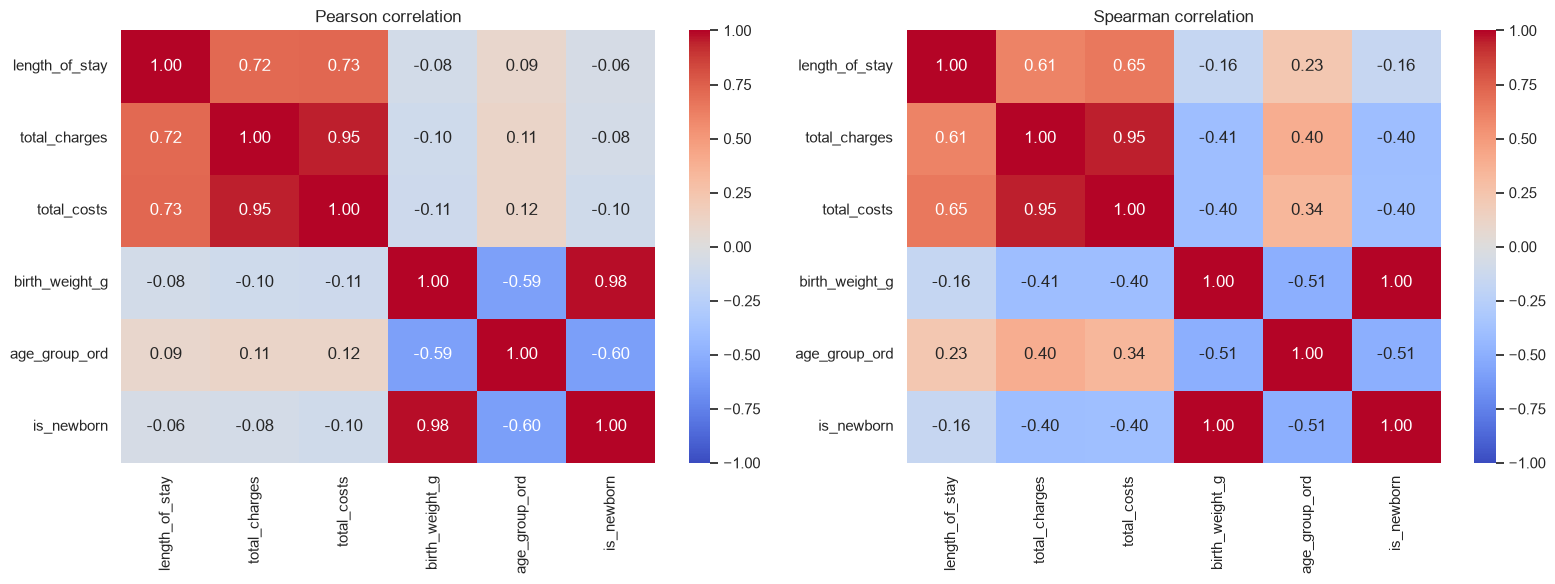

In [16]:
# 16. Numeric relationships (exploratory only; charges/costs are post-discharge)
num_cols = ['length_of_stay', 'total_charges', 'total_costs', 'birth_weight_g',
            'age_group_ord', 'is_newborn']
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, method in zip(axes, ['pearson', 'spearman']):
    sns.heatmap(df[num_cols].corr(method=method), annot=True, cmap='coolwarm',
                fmt='.2f', vmin=-1, vmax=1, ax=ax)
    ax.set_title(f'{method.capitalize()} correlation')
plt.tight_layout()
plt.show()

#### Results: numeric correlations (exploratory only)

| Pair | Pearson | Spearman |
|---|---:|---:|
| LOS vs. total charges | 0.72 | 0.61 |
| LOS vs. total costs | 0.73 | 0.65 |
| Charges vs. costs | 0.95 | 0.95 |
| LOS vs. age group (ordinal) | 0.09 | 0.23 |
| LOS vs. birth weight | -0.08 | -0.16 |
| LOS vs. newborn flag | -0.06 | -0.16 |

- Charges and costs track LOS closely, but they are **only known after discharge**, so they are excluded from the admission-time model (they would be target leakage).
- Age and birth weight are weakly related to LOS in a linear sense; Spearman values are higher, so part of the relationship is monotonic but non-linear.

> **Takeaway:** the strongest numeric correlates of LOS are post-discharge quantities. Genuinely available predictors correlate only weakly with LOS.

<a id="sec6"></a>
## 6. Feature-timing audit and data splits

Separate fields available at admission from fields only known at discharge, define three feature sets, and create train, validation and test partitions.

**Prediction-time convention:** Set A contains candidate admission-time fields. Sets B/C use discharge-derived clinical codes and are retrospective comparisons only. Model selection occurs exclusively on validation data; the test set is reserved for a single final evaluation. Tail-aware weighting is an experiment, not a guaranteed improvement.


Set A (admission candidate): ['gender', 'race', 'ethnicity', 'type_of_admission', 'payment_typology_1', 'permanent_facility_id', 'zip_code_3_digits', 'age_group_ord', 'emergency_department_flag', 'has_secondary_payer']
Set B (retrospective, clinical codes): ['gender', 'race', 'ethnicity', 'type_of_admission', 'payment_typology_1', 'permanent_facility_id', 'zip_code_3_digits', 'apr_mdc_description', 'apr_medical_surgical_description', 'ccs_diagnosis_code', 'age_group_ord', 'emergency_department_flag', 'has_secondary_payer']
Target/post-discharge variables excluded from admission model: ['length_of_stay', 'los_log', 'los_capped', 'los_censored', 'patient_disposition', 'total_charges', 'total_costs', 'apr_severity_of_illness_code', 'apr_severity_of_illness_description', 'apr_risk_of_mortality', 'apr_drg_code', 'apr_drg_description', 'ccs_procedure_code', 'ccs_procedure_description', 'is_newborn', 'birth_weight_g']

LOS by apr_severity_of_illness_description


,count,mean,median,std
apr_severity_of_illness_description,,,,
Extreme,24343,15.27,10.00,18.48
Major,85746,6.72,5.00,7.57
Moderate,133749,4.43,3.00,5.59
Minor,107723,3.03,2.00,3.55


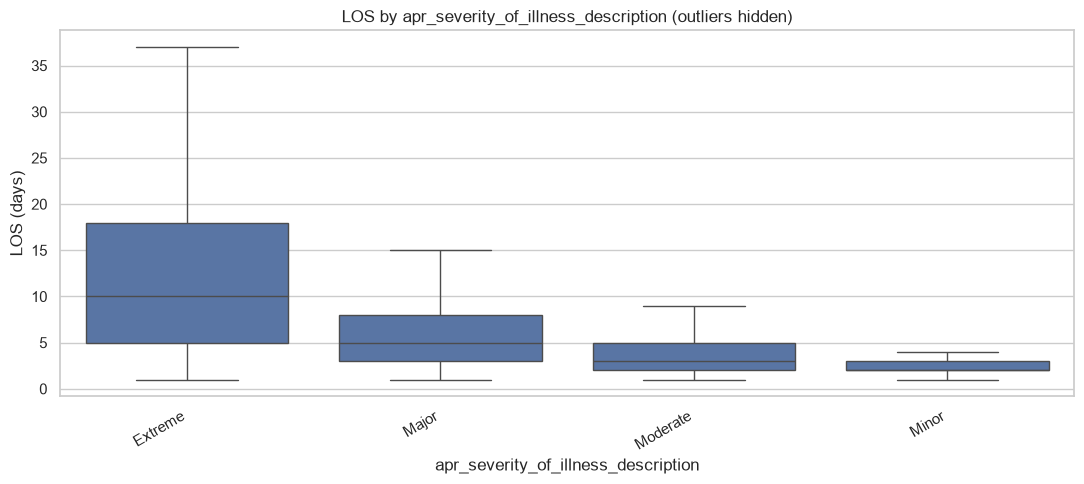


LOS by apr_risk_of_mortality


,count,mean,median,std
apr_risk_of_mortality,,,,
Extreme,21422,13.51,8.00,17.19
Major,57111,7.55,5.00,9.33
Moderate,79416,5.16,4.00,6.48
Minor,193612,3.80,2.00,5.18


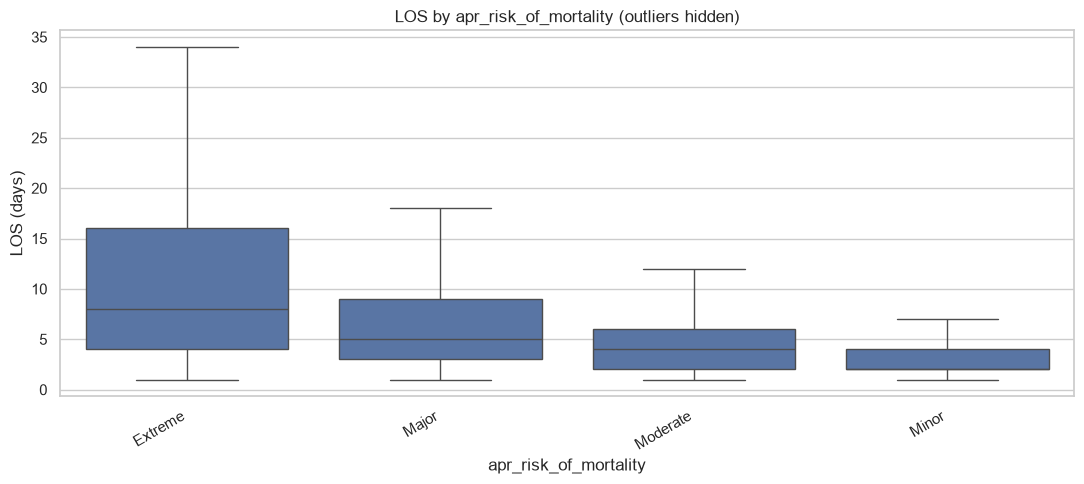


LOS by patient_disposition


,count,mean,median,std
patient_disposition,,,,
Hospice - Medical Facility,2959,9.70,6.00,12.39
Inpatient Rehabilitation Facility,4990,10.18,6.00,12.53
Hospice - Home,1497,8.36,6.00,8.58
Skilled Nursing Home,41088,8.47,5.00,10.76
Expired,8481,8.75,4.00,14.47
Home w/ Home Health Services,54786,6.70,4.00,8.98
Home or Self Care,220598,4.04,3.00,5.60
Psychiatric Hospital or Unit of Hosp,1550,9.24,3.00,16.70
Short-term Hospital,6416,5.08,2.00,9.52


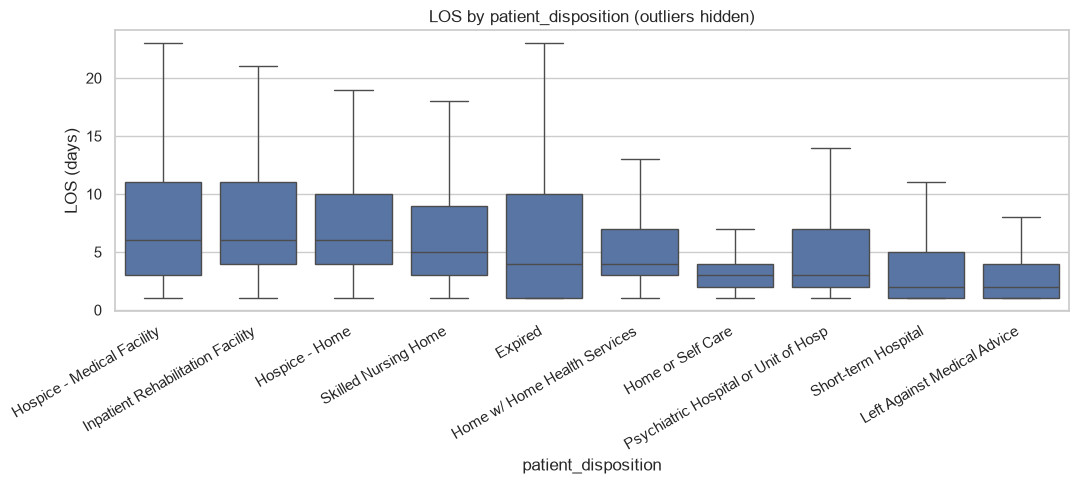

In [17]:
# 17. Feature timing audit: keep the admission-time model free of discharge-coded fields.
# A is the prospective model. The exact timing of each retained field must still be
# verified against the hospital's actual admission workflow.
cat_A = ['gender', 'race', 'ethnicity', 'type_of_admission',
         'payment_typology_1', 'permanent_facility_id', 'zip_code_3_digits']
num_A = ['age_group_ord', 'emergency_department_flag', 'has_secondary_payer']

# Birth-weight-derived fields are omitted from A because they may only be established
# after birth (and do not have reliable at-admission availability for all encounters).
# B/C are explicitly retrospective analyses, NOT deployable admission-time models.
cat_B = cat_A + ['apr_mdc_description', 'apr_medical_surgical_description',
                 'ccs_diagnosis_code']
num_B = num_A

excluded = ['length_of_stay', 'los_log', 'los_capped', 'los_censored',
            'patient_disposition', 'total_charges', 'total_costs',
            'apr_severity_of_illness_code', 'apr_severity_of_illness_description',
            'apr_risk_of_mortality', 'apr_drg_code', 'apr_drg_description',
            'ccs_procedure_code', 'ccs_procedure_description',
            'is_newborn', 'birth_weight_g']
assert not (set(cat_A + num_A) & set(excluded))
print('Set A (admission candidate):', cat_A + num_A)
print('Set B (retrospective, clinical codes):', cat_B + num_B)
print('Target/post-discharge variables excluded from admission model:', excluded)

# Exploratory only; these columns must never be passed into admission-time prediction.
for c in ['apr_severity_of_illness_description', 'apr_risk_of_mortality',
          'patient_disposition']:
    los_by(c, top_n=10)


#### Results: feature sets

| Set | Purpose | Features | Contents |
|---|---|---:|---|
| **A** | Admission-time candidate (the model that could be deployed) | 10 | gender, race, ethnicity, admission type, primary payer, facility ID, zip prefix, age group, ED flag, secondary-payer flag |
| **B** | Retrospective comparison | 13 | A + MDC category, medical/surgical, CCS diagnosis |
| **C** | Retrospective comparison | 15 | B + severity of illness, risk of mortality |

Sixteen fields are **excluded** from the admission model, including the target variants, disposition, charges, costs, severity, risk of mortality, DRG, procedure, newborn flag and birth weight.

**Why those exclusions matter.** LOS rises steeply with discharge-coded severity and risk:

| Severity of illness | Mean LOS | Risk of mortality | Mean LOS |
|---|---:|---|---:|
| Minor | 3.03 | Minor | 3.80 |
| Moderate | 4.43 | Moderate | 5.16 |
| Major | 6.72 | Major | 7.55 |
| Extreme | **15.27** (median 10) | Extreme | **13.51** (median 8) |

Disposition is also tied to LOS (home/self-care 4.04 days vs. 8.4 to 10.2 days for skilled nursing, hospice and inpatient rehabilitation), but is known only at discharge.

> **Takeaway:** the most predictive fields are discharge-coded, so Sets B and C are *upper-bound benchmarks* and must not be presented as admission-time predictors.


### Model-ready preprocessing (fit on training data only)


In [18]:
# 18. THREE-way split and train-only preprocessing (no test-set model selection).
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, FunctionTransformer

# All rows remain in exactly one partition: 64% train, 16% validation, 20% test.
# A random holdout estimates within-year performance, NOT future-year or unseen-hospital performance.
los_bins = pd.qcut(df['length_of_stay'], q=10, duplicates='drop')
trainval_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=42, stratify=los_bins)
train_idx, val_idx = train_test_split(
    trainval_idx, test_size=0.20, random_state=43,
    stratify=los_bins.loc[trainval_idx])
train_idx, val_idx, test_idx = map(pd.Index, (train_idx, val_idx, test_idx))
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx)
            or set(val_idx) & set(test_idx))

# Keep imputation within the fitted transformer so validation/test are never used
# to calculate imputation medians, category frequencies, or scaling parameters.
def make_preprocessor(cat_features, num_features):
    cat_pipe = Pipeline([
        ('normalize_missing', FunctionTransformer(
            lambda x: x.astype('object').where(pd.notna(x), np.nan), validate=False)),
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                 min_frequency=0.001, sparse_output=True))])
    num_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())])
    return ColumnTransformer([
        ('cat', cat_pipe, cat_features), ('num', num_pipe, num_features)])

# For the tree model, use compact ordinal-encoded categoricals instead of
# materializing a huge one-hot/dense array. Only the training split fits this.
def make_tree_preprocessor(cat_features, num_features):
    return ColumnTransformer([
        ('cat', Pipeline([
            ('normalize_missing', FunctionTransformer(
                lambda x: x.astype('object').where(pd.notna(x), np.nan), validate=False)),
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OrdinalEncoder(handle_unknown='use_encoded_value',
                                      unknown_value=-1, max_categories=100))
        ]), cat_features),
        ('num', SimpleImputer(strategy='median'), num_features)
    ], sparse_threshold=0)

print(f'Train: {len(train_idx):,} | Validation: {len(val_idx):,} | Test: {len(test_idx):,}')
print('No model or preprocessing step is fitted to validation/test data.')


Train: 225,014 | Validation: 56,254 | Test: 70,318
No model or preprocessing step is fitted to validation/test data.


#### Results: train / validation / test split

| Partition | Rows | Share | Role |
|---|---:|---:|---|
| Train | 225,014 | 64% | Fit models and preprocessing |
| Validation | 56,254 | 16% | Tune and select models |
| Test | 70,318 | 20% | Single final evaluation |

The split is stratified on LOS deciles so all three partitions have a similar LOS distribution. All imputation, encoding and scaling are fitted on the training partition only. Because this is a random split within one year, it measures within-year performance, not accuracy for future years or unseen hospitals.

In [19]:
# 19. Final check
print('Final dataset dimensions:', df.shape)
display(df.isnull().sum().sort_values(ascending=False).head(15).to_frame('Remaining missing'))

Final dataset dimensions: (351586, 36)


,Remaining missing
hospital_service_area,755
hospital_county,755
apr_severity_of_illness_description,25
apr_risk_of_mortality,25
apr_medical_surgical_description,1
apr_severity_of_illness_code,1
emergency_department_flag,1
total_costs,1
total_charges,1
emergency_department_indicator,1


#### Results: final data check

The analytic table has **351,586 rows x 36 columns**. Remaining missing values are limited to:

- 755 rows in `hospital_service_area` and `hospital_county` (not used as model features),
- 25 rows in the severity and mortality fields (Sets B/C only, imputed inside the train-fitted pipeline),
- 1 row each in charges, costs, ED indicator and medical/surgical fields.

> **Takeaway:** the table is model-ready. The remaining gaps are either in columns that are not model features or are handled by imputers fitted on the training partition only.

<a id="sec7"></a>
## 7. Model development and validation

**Candidates:** Linear Regression, Ridge, Elastic Net, RBF-SVR, HistGradientBoosting (Poisson loss), XGBoost, LightGBM, CatBoost, plus "tail-aware" variants that up-weight stays longer than 20 days.
**Selection rule (validation only):** `selection_score = RMSE + 0.10 x MAE on stays over 20 days`. Lower is better.

### Predictive modeling

In [20]:
# 20. Set up TRAIN/VALIDATION matrices. Keep the test partition sealed.
import time, warnings
from joblib import Parallel, delayed
from scipy import sparse
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings('ignore', category=UserWarning)

y_tr = df.loc[train_idx, 'length_of_stay'].to_numpy(dtype=float)
y_val = df.loc[val_idx, 'length_of_stay'].to_numpy(dtype=float)
ylog_tr = np.log1p(y_tr)

# Retrospective feature sets are available for research comparison, but selection
# for an *admission-time* model must use Set A only.
for c in ['apr_severity_of_illness_description', 'apr_risk_of_mortality']:
    df[c] = df[c].astype('string').fillna('Unknown').astype('category')
cat_C = cat_B + ['apr_severity_of_illness_description', 'apr_risk_of_mortality']
num_C = num_B
FEATURE_SETS = {'A': (cat_A, num_A), 'B': (cat_B, num_B), 'C': (cat_C, num_C)}

M = {}
for fs, (cats, nums) in FEATURE_SETS.items():
    prep = make_preprocessor(cats, nums)
    Xtr = sparse.csr_matrix(prep.fit_transform(df.loc[train_idx, cats + nums]))
    Xval = sparse.csr_matrix(prep.transform(df.loc[val_idx, cats + nums]))
    M[fs] = dict(prep=prep, Xtr=Xtr, Xval=Xval)
    print(f'Set {fs}: train {Xtr.shape}, validation {Xval.shape}')

rng = np.random.default_rng(42)
tune_pos = rng.choice(len(train_idx), min(150_000, len(train_idx)), replace=False)
val_eval_pos = rng.choice(len(val_idx), min(100_000, len(val_idx)), replace=False)
svr_pos = rng.choice(len(train_idx), min(50_000, len(train_idx)), replace=False)
svr_tune_pos = rng.choice(svr_pos, min(10_000, len(svr_pos)), replace=False)
svr_smear_pos = rng.choice(np.setdiff1d(np.arange(len(train_idx)), svr_pos),
                           min(20_000, len(train_idx) - len(svr_pos)), replace=False)
cv3 = KFold(n_splits=3, shuffle=True, random_state=42)


Set A: train (225014, 98), validation (56254, 98)
Set B: train (225014, 261), validation (56254, 261)
Set C: train (225014, 271), validation (56254, 271)


#### Results: design matrices

After train-fitted one-hot encoding: **Set A = 98 columns, Set B = 261, Set C = 271** (225,014 training rows, 56,254 validation rows each). The jump from A to B and C comes from the high-cardinality clinical codes.

In [21]:
# 21. Scoring, conservative inverse transform and validation bookkeeping.
def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

def score(y, p):
    return {'MAE': mean_absolute_error(y, p), 'RMSE': rmse(y, p),
            'R2': r2_score(y, p), 'Bias': float(np.mean(p - y))}

def tail_score(y, p, threshold=20):
    mask = y > threshold
    return {'MAE_21plus': float(mean_absolute_error(y[mask], p[mask])) if mask.any() else np.nan,
            'Bias_21plus': float(np.mean(p[mask] - y[mask])) if mask.any() else np.nan,
            'N_21plus': int(mask.sum())}

def back_transform(pred_log, smear):
    return np.maximum(np.exp(np.minimum(pred_log, 30)) * smear - 1, 1)

def dense32(X):
    return X.toarray().astype('float32')

def svr_predict(model, X, chunk=5000):
    parts = Parallel(n_jobs=-1)(
        delayed(model.predict)(dense32(X[i:i + chunk]))
        for i in range(0, X.shape[0], chunk))
    return np.concatenate(parts)

rows = []
val_pred = {}        # model predictions on validation only
fitted = {}          # model fit using training only
best_params = {}
smearing = {}

def record(fs, name, pred_val, secs, model, predict_kind='log'):
    val_pred[(fs, name)] = pred_val
    fitted[(fs, name)] = model
    ix = val_eval_pos
    p, y = pred_val[ix], y_val[ix]
    ok = np.isfinite(p)
    s = score(y[ok], p[ok])
    tail = tail_score(y[ok], p[ok])
    # A transparent joint criterion: general accuracy + long-stay accuracy.
    # The held-out TEST set is not used to compute it.
    selection_score = s['RMSE'] + 0.10 * tail['MAE_21plus']
    rows.append({'feature_set': fs, 'model': name, **s, **tail,
                 'selection_score': selection_score,
                 'fit_minutes': round(secs / 60, 1)})
    print(f'{fs} | {name:30s} val RMSE {s["RMSE"]:.3f}  '
          f'val MAE(21+) {tail["MAE_21plus"]:.3f}  '
          f'bias(21+) {tail["Bias_21plus"]:+.3f}')

def fit_log_model(model, Xtr, Xval, key):
    model.fit(Xtr, ylog_tr)
    # Smearing uses TRAINING residuals only; does not touch validation or test.
    smear = float(np.mean(np.exp(ylog_tr - model.predict(Xtr))))
    smearing[key] = smear
    return back_transform(model.predict(Xval), smear), model


In [22]:
# 22. Linear models: tune on TRAIN CV, compare on VALIDATION, never test.
for fs, d in M.items():
    Xtr, Xval = d['Xtr'], d['Xval']
    print(f'\n=== Feature set {fs} ===')

    t = time.time()
    pred, mdl = fit_log_model(LinearRegression(), Xtr, Xval,
                              (fs, 'Linear Regression'))
    record(fs, 'Linear Regression', pred, time.time() - t, mdl)

    t = time.time()
    raw = LinearRegression().fit(Xtr, y_tr)
    record(fs, 'Linear Regression (raw target)',
           np.maximum(raw.predict(Xval), 1), time.time() - t, raw)

    t = time.time()
    gs = GridSearchCV(Ridge(), {'alpha': [1, 10, 100, 1000, 10000]},
                      scoring='neg_root_mean_squared_error', cv=cv3, n_jobs=3)
    gs.fit(Xtr[tune_pos], ylog_tr[tune_pos])
    alpha_full = gs.best_params_['alpha'] * len(ylog_tr) / (len(tune_pos) * 2 / 3)
    best_params[(fs, 'Ridge')] = {'alpha_cv': gs.best_params_['alpha'],
                                  'alpha_full': alpha_full}
    pred, mdl = fit_log_model(Ridge(alpha=alpha_full), Xtr, Xval, (fs, 'Ridge'))
    record(fs, 'Ridge', pred, time.time() - t, mdl)

    t = time.time()
    gs = GridSearchCV(ElasticNet(max_iter=300, tol=1e-3,
                                 selection='random', random_state=42),
                      {'alpha': [1e-4, 1e-3, 1e-2], 'l1_ratio': [0.2, 0.5, 0.9]},
                      scoring='neg_root_mean_squared_error', cv=cv3, n_jobs=3)
    gs.fit(Xtr[tune_pos], ylog_tr[tune_pos])
    best_params[(fs, 'Elastic Net')] = gs.best_params_
    en = ElasticNet(**gs.best_params_, max_iter=1000, tol=1e-4,
                    selection='random', random_state=42)
    pred, mdl = fit_log_model(en, Xtr, Xval, (fs, 'Elastic Net'))
    record(fs, 'Elastic Net', pred, time.time() - t, mdl)
    print('    nonzero Elastic Net coefficients:', int((mdl.coef_ != 0).sum()))

print('Training-CV hyperparameters:', best_params)



=== Feature set A ===
A | Linear Regression              val RMSE 7.478  val MAE(21+) 29.221  bias(21+) -29.212
A | Linear Regression (raw target) val RMSE 7.455  val MAE(21+) 28.731  bias(21+) -28.731
A | Ridge                          val RMSE 7.478  val MAE(21+) 29.227  bias(21+) -29.218
A | Elastic Net                    val RMSE 7.479  val MAE(21+) 29.275  bias(21+) -29.271
    nonzero Elastic Net coefficients: 90

=== Feature set B ===
B | Linear Regression              val RMSE 7.100  val MAE(21+) 27.028  bias(21+) -27.021
B | Linear Regression (raw target) val RMSE 7.065  val MAE(21+) 25.994  bias(21+) -25.992
B | Ridge                          val RMSE 7.100  val MAE(21+) 27.039  bias(21+) -27.032
B | Elastic Net                    val RMSE 7.108  val MAE(21+) 27.149  bias(21+) -27.146
    nonzero Elastic Net coefficients: 246

=== Feature set C ===
C | Linear Regression              val RMSE 6.617  val MAE(21+) 24.433  bias(21+) -24.341
C | Linear Regression (raw target) val

#### Results: linear models (validation)

| Feature set | Linear (log target) RMSE | Linear (raw target) RMSE | Ridge RMSE | Elastic Net RMSE | Long-stay (21+) bias |
|---|---:|---:|---:|---:|---:|
| **A** | 7.478 | 7.455 | 7.478 | 7.479 | about -29 days |
| **B** | 7.100 | 7.065 | 7.100 | 7.108 | about -26 to -27 days |
| **C** | 6.617 | 6.592 | 6.617 | 6.625 | about -22 to -24 days |

- **Regularization changes almost nothing.** Ridge matches ordinary least squares, and the cross-validated penalties sit at the low end of their grids (Ridge alpha = 1, Elastic Net alpha = 0.0001). With 225k rows and under 300 columns, over-fitting is not the problem.
- Elastic Net retains 90 / 246 / 256 non-zero coefficients for sets A / B / C.
- Clinical information helps: RMSE falls from 7.48 (A) to 6.62 (C).
- Every linear model **underpredicts long stays by roughly the whole excess** (21+ day bias of -22 to -29 days).

> **Takeaway:** the linear ceiling on admission-time information is high error and a large systematic tail miss, motivating non-linear models.

In [ ]:
# 23. Nonlinear models: SVR and a long-stay-aware boosting candidate.
# SVR is computationally expensive; fit it on 50k train rows, tune on 10k.
SVR_SETS = ['A', 'B', 'C']
for fs in SVR_SETS:
    Xtr, Xval = M[fs]['Xtr'], M[fs]['Xval']
    t = time.time()
    gs = GridSearchCV(SVR(kernel='rbf', cache_size=1000),
                      {'C': [1, 10], 'epsilon': [0.1, 0.3],
                       'gamma': ['scale', 0.01]},
                      scoring='neg_root_mean_squared_error', cv=cv3, n_jobs=3)
    gs.fit(dense32(Xtr[svr_tune_pos]), ylog_tr[svr_tune_pos])
    best_params[(fs, 'RBF-SVR')] = gs.best_params_
    svr = SVR(kernel='rbf', cache_size=1000, **gs.best_params_)
    svr.fit(dense32(Xtr[svr_pos]), ylog_tr[svr_pos])
    smear_resid = ylog_tr[svr_smear_pos] - svr_predict(svr, Xtr[svr_smear_pos])
    smearing[(fs, 'RBF-SVR')] = float(np.mean(np.exp(smear_resid)))
    # Predict all validation rows to permit fair category-level comparisons.
    pred = back_transform(svr_predict(svr, Xval), smearing[(fs, 'RBF-SVR')])
    record(fs, 'RBF-SVR', pred, time.time() - t, svr)

# Two variants of histogram gradient boosting on raw LOS:
# - standard: optimize usual Poisson deviance, suitable for positive/skewed LOS
# - tail-aware: train with extra weight on LOS > 20 days to address underprediction.
# Both are evaluated on the SAME unweighted validation rows.
# Training weights are a modeling choice, not evidence of improvement by themselves.
TREE_SETS = ['A', 'B', 'C']
tree_preps = {}
for fs in TREE_SETS:
    cats, nums = FEATURE_SETS[fs]
    t = time.time()
    tree_prep = make_tree_preprocessor(cats, nums)
    tree_pos = rng.choice(len(train_idx), min(300_000, len(train_idx)), replace=False)
    Xt_tr = tree_prep.fit_transform(df.loc[train_idx[tree_pos], cats + nums])
    Xt_val = tree_prep.transform(df.loc[val_idx, cats + nums])
    tree_preps[fs] = tree_prep
    cat_mask = [True] * len(cats) + [False] * len(nums)
    for name, weights in [
        ('HistGB Poisson', None),
        ('HistGB Poisson (tail-aware)', np.where(y_tr[tree_pos] > 20, 4., 1.))
    ]:
        start = time.time()
        model = HistGradientBoostingRegressor(
            loss='poisson', max_iter=180, learning_rate=0.07,
            max_leaf_nodes=31, l2_regularization=1.0,
            categorical_features=cat_mask, random_state=42)
        model.fit(Xt_tr, y_tr[tree_pos], sample_weight=weights)
        pred = np.maximum(model.predict(Xt_val), 1)
        record(fs, name, pred, time.time() - start, model, predict_kind='raw')
    print(f'Tree preparation for set {fs}: {time.time() - t:.1f}s total')


### Additional models: XGBoost, LightGBM and CatBoost

**Evaluation design:** Only Feature Set **A** is used for the new admission-time modeling experiments. Parameters are selected on **validation** (never test). The 2015 random holdout measures within-year generalization, not future deployment accuracy. B/C remain retrospective comparisons. Set `BOOST_TRAIN_MAX` and `N_TRIALS` to manage compute. The new models predict **LOS in days** directly.

In [ ]:
# 23A. Model preparation (no test data accessed)

#%pip install -U xgboost lightgbm catboost shap scipy
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import ParameterSampler
from sklearn.base import clone

BOOST_SETS = ['A']                 # admission-time predictor set only
BOOST_TRAIN_MAX = 200_000          # increase for final experiments if resources allow
BOOST_TUNE_MAX = 100_000           # tune on a fixed TRAIN-only subsample
BOOST_VAL_MAX = 60_000             # fixed VALIDATION-only comparison subset
N_TRIALS = 5                       # per model; increase for a more thorough search
BOOST_SEED = 42
boost_rng = np.random.default_rng(BOOST_SEED)
boost_train_pos = boost_rng.choice(len(train_idx), min(BOOST_TRAIN_MAX, len(train_idx)), replace=False)
boost_tune_pos = boost_rng.choice(boost_train_pos, min(BOOST_TUNE_MAX, len(boost_train_pos)), replace=False)
boost_val_pos = np.sort(boost_rng.choice(len(val_idx), min(BOOST_VAL_MAX, len(val_idx)), replace=False))

# For XGBoost / LightGBM, each categorical value becomes an ordinal code.
# The ordinal code is an ID, not an ordinal clinical measure. Tree splitting can
# still be imperfect for nominal categories; CatBoost uses native strings below.
boost_preps = {}
boost_data = {}
for fs in BOOST_SETS:
    cats, nums = FEATURE_SETS[fs]
    prep = make_tree_preprocessor(cats, nums)
    tr_raw = df.loc[train_idx[boost_train_pos], cats + nums]
    va_raw = df.loc[val_idx, cats + nums]
    Xt = np.asarray(prep.fit_transform(tr_raw), dtype=np.float32)
    Xv = np.asarray(prep.transform(va_raw), dtype=np.float32)
    boost_preps[fs] = prep
    boost_data[fs] = (Xt, Xv)
    print(f'{fs} boosting matrices: train {Xt.shape}; validation {Xv.shape}')

# CatBoost: use the original category labels, converted to strings, and
# numerical medians learned ONLY from the BOOST training split.
catboost_num_medians = {}
for fs in BOOST_SETS:
    cats, nums = FEATURE_SETS[fs]
    frame = df.loc[train_idx[boost_train_pos], nums].apply(pd.to_numeric, errors='coerce')
    catboost_num_medians[fs] = frame.median().fillna(0.0)

def catboost_frame(frame, fs):
    cats, nums = FEATURE_SETS[fs]
    result = pd.DataFrame(index=frame.index)
    for c in cats:
        result[c] = frame[c].astype('string').fillna('__MISSING__').astype(str)
    for c in nums:
        result[c] = pd.to_numeric(frame[c], errors='coerce').fillna(
            catboost_num_medians[fs].loc[c]).astype('float32')
    return result[cats + nums]

catboost_data = {}
for fs in BOOST_SETS:
    cats, nums = FEATURE_SETS[fs]
    cbtr = catboost_frame(df.loc[train_idx[boost_train_pos]], fs)
    cbva = catboost_frame(df.loc[val_idx], fs)
    catboost_data[fs] = (cbtr, cbva)

print('Tuning is performed using TRAIN and VALIDATION only.')


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   --- ------------------------------------ 4.5/48.9 MB 21.9 MB/s eta 0:00:03
   ------- -------------------------------- 9.7/48.9 MB 23.5 MB/s eta 0:00:02
   ------------- -------------------------- 16.0/48.9 MB 25.7 MB/s eta 0:00:02
   ------------------ --------------------- 22.3/48.9 MB 26.9 MB/s eta 0:00:01
   ----------------------- ---------------- 28.8/48.9 MB 27.4 MB/s eta 0:00:01
   --------------------------- ------------ 34.1/48.9 MB 27.0 MB/s eta 0:00:01
   -------------------------------- ------- 40.1/48.9 MB 27.4 MB/s eta 0:00:01
   ------------------------------------- -- 45.6/48.9 MB 27.5 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 27.4 MB/s eta 0:00:01
   -------------------------------

In [ ]:
# 23B. Hyperparameter optimization on validation; final test remains untouched
# The tuning score prioritizes overall RMSE plus a smaller long-stay MAE penalty.
# A fixed validation subset makes comparisons consistent across trials.
BOOST_GRIDS = {
    'XGBoost': {
        'n_estimators': [250, 400, 600],
        'max_depth': [4, 6, 8],
        'learning_rate': [0.03, 0.05, 0.08],
        'subsample': [0.8, 1.0],
        'colsample_bytree': [0.8, 1.0],
        'min_child_weight': [3, 10]
    },
    'LightGBM': {
        'n_estimators': [250, 400, 600],
        'num_leaves': [15, 31, 63],
        'learning_rate': [0.03, 0.05, 0.08],
        'min_child_samples': [30, 80, 150],
        'subsample': [0.8, 1.0],
        'colsample_bytree': [0.8, 1.0]
    },
    'CatBoost': {
        'iterations': [300, 500, 700],
        'depth': [4, 6, 8],
        'learning_rate': [0.03, 0.05, 0.08],
        'l2_leaf_reg': [3, 8, 15]
    }
}

def construct_boost_model(name, params, fs):
    if name == 'XGBoost':
        return XGBRegressor(objective='reg:squarederror', tree_method='hist',
                            n_jobs=4, random_state=BOOST_SEED, **params)
    if name == 'LightGBM':
        return LGBMRegressor(objective='regression', verbosity=-1,
                             n_jobs=4, random_state=BOOST_SEED, **params)
    if name == 'CatBoost':
        cats, _ = FEATURE_SETS[fs]
        return CatBoostRegressor(loss_function='RMSE', cat_features=cats,
                                 verbose=False, thread_count=4,
                                 random_seed=BOOST_SEED, allow_writing_files=False,
                                 **params)
    raise KeyError(name)

boost_search_results = []
boost_best = {}
for fs in BOOST_SETS:
    Xt, Xv = boost_data[fs]
    cbtr, cbva = catboost_data[fs]
    # Positions in the original training split for the boost training rows
    tune_in_boost = np.flatnonzero(np.isin(boost_train_pos, boost_tune_pos))
    for name in ('XGBoost', 'LightGBM', 'CatBoost'):
        settings = list(ParameterSampler(BOOST_GRIDS[name], n_iter=N_TRIALS,
                                        random_state=BOOST_SEED))
        best = None
        print(f'\nTuning {name} / Set {fs} ({len(settings)} trials)')
        for trial, params in enumerate(settings, start=1):
            model = construct_boost_model(name, params, fs)
            if name == 'CatBoost':
                xtrain, xval = cbtr.iloc[tune_in_boost], cbva.iloc[boost_val_pos]
            else:
                xtrain, xval = Xt[tune_in_boost], Xv[boost_val_pos]
            t0 = time.time()
            model.fit(xtrain, y_tr[boost_train_pos[tune_in_boost]])
            pp = np.maximum(np.asarray(model.predict(xval), dtype=float), 1.)
            yt = y_val[boost_val_pos]
            mt = score(yt, pp)
            tail = tail_score(yt, pp)
            criterion = mt['RMSE'] + 0.10 * tail['MAE_21plus']
            boost_search_results.append({'feature_set': fs, 'model': name,
                'trial': trial, **params, 'validation_RMSE': mt['RMSE'],
                'validation_MAE_21plus': tail['MAE_21plus'],
                'selection_score': criterion, 'seconds': time.time()-t0})
            if best is None or criterion < best['criterion']:
                best = {'params': params, 'criterion': criterion}
            print(f'  trial {trial}: RMSE={mt["RMSE"]:.3f}, tail MAE={tail["MAE_21plus"]:.3f}')
        boost_best[(fs, name)] = best
        best_params[(fs, name)] = best['params']
        print(f'Best {name}: {best["params"]}')

boost_search_df = pd.DataFrame(boost_search_results)
display(boost_search_df.sort_values('selection_score').head(12).round(3))



Tuning XGBoost / Set A (5 trials)
  trial 1: RMSE=7.356, tail MAE=27.598
  trial 2: RMSE=7.404, tail MAE=27.445
  trial 3: RMSE=7.356, tail MAE=27.759
  trial 4: RMSE=7.378, tail MAE=27.540
  trial 5: RMSE=7.354, tail MAE=27.988
Best XGBoost: {'subsample': 1.0, 'n_estimators': 400, 'min_child_weight': 10, 'max_depth': 6, 'learning_rate': 0.08, 'colsample_bytree': 1.0}

Tuning LightGBM / Set A (5 trials)
  trial 1: RMSE=7.344, tail MAE=27.815
  trial 2: RMSE=7.344, tail MAE=27.922
  trial 3: RMSE=7.365, tail MAE=27.502
  trial 4: RMSE=7.345, tail MAE=27.860
  trial 5: RMSE=7.384, tail MAE=28.450
Best LightGBM: {'subsample': 1.0, 'num_leaves': 63, 'n_estimators': 400, 'min_child_samples': 80, 'learning_rate': 0.08, 'colsample_bytree': 0.8}

Tuning CatBoost / Set A (5 trials)
  trial 1: RMSE=7.360, tail MAE=28.190
  trial 2: RMSE=7.382, tail MAE=28.390
  trial 3: RMSE=7.361, tail MAE=28.124
  trial 4: RMSE=7.351, tail MAE=28.091
  trial 5: RMSE=7.363, tail MAE=28.183
Best CatBoost: {'lea

,feature_set,model,trial,subsample,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree,validation_RMSE,validation_MAE_21plus,selection_score,seconds,num_leaves,min_child_samples,l2_leaf_reg,iterations,depth
7,A,LightGBM,3,1.00,400.00,NaN,NaN,0.08,0.80,7.37,27.50,10.12,1.23,63.00,80.00,NaN,NaN,NaN
0,A,XGBoost,1,1.00,400.00,10.00,6.00,0.08,1.00,7.36,27.60,10.12,1.25,NaN,NaN,NaN,NaN,NaN
5,A,LightGBM,1,0.80,400.00,NaN,NaN,0.08,0.80,7.34,27.82,10.12,0.77,15.00,80.00,NaN,NaN,NaN
8,A,LightGBM,4,1.00,400.00,NaN,NaN,0.03,0.80,7.34,27.86,10.13,1.04,31.00,30.00,NaN,NaN,NaN
2,A,XGBoost,3,0.80,250.00,10.00,8.00,0.03,1.00,7.36,27.76,10.13,1.44,NaN,NaN,NaN,NaN,NaN
3,A,XGBoost,4,1.00,400.00,10.00,8.00,0.05,1.00,7.38,27.54,10.13,1.53,NaN,NaN,NaN,NaN,NaN
6,A,LightGBM,2,0.80,250.00,NaN,NaN,0.08,0.80,7.34,27.92,10.14,0.47,15.00,30.00,NaN,NaN,NaN
1,A,XGBoost,2,1.00,400.00,10.00,8.00,0.08,1.00,7.40,27.45,10.15,1.49,NaN,NaN,NaN,NaN,NaN
4,A,XGBoost,5,1.00,400.00,3.00,6.00,0.03,0.80,7.35,27.99,10.15,1.27,NaN,NaN,NaN,NaN,NaN
13,A,CatBoost,4,NaN,NaN,NaN,NaN,0.05,NaN,7.35,28.09,10.16,21.48,NaN,NaN,8.00,300.00,6.00


#### Results: hyperparameter search for XGBoost, LightGBM and CatBoost (Set A)

| Model | Best trial | Validation RMSE (5 trials) | Tail MAE (21+) | Typical fit time |
|---|---|---|---:|---:|
| XGBoost | 400 trees, depth 6, lr 0.08, min child weight 10 | 7.354 to 7.404 | 27.4 to 28.0 | about 1.3 s |
| LightGBM | 400 trees, 63 leaves, lr 0.08, min child samples 80 | 7.344 to 7.384 | 27.5 to 28.5 | about 0.5 to 1.2 s |
| CatBoost | 300 iterations, depth 6, lr 0.05, L2 8 | 7.351 to 7.382 | 28.1 to 28.4 | 21 to 33 s |

- "Best trial" is chosen by the selection score (RMSE + 0.10 x long-stay MAE) on a validation subsample; tuning used a 100k-row training subsample. The three selected configurations are within about **0.015 RMSE** of each other.
- The spread across trials is small (about 0.05 RMSE), so hyperparameters matter much less than the information in the features.
- CatBoost is more than an order of magnitude slower per trial (about 20 to 30 s vs. 1 to 1.5 s) for no accuracy gain.

> **Takeaway:** the models are limited by the signal in Set A, not by tuning. A larger search is unlikely to change conclusions.

In [ ]:
# 23C. Refit each tuned model on the defined BOOST training subset.
# Evaluate on the entire validation partition so it is comparable with
# the existing candidate models via record() and the shared val_eval_pos.
for fs in BOOST_SETS:
    Xt, Xv = boost_data[fs]
    cbtr, cbva = catboost_data[fs]
    for name in ('XGBoost', 'LightGBM', 'CatBoost'):
        t0 = time.time()
        model = construct_boost_model(name, boost_best[(fs, name)]['params'], fs)
        if name == 'CatBoost':
            model.fit(cbtr, y_tr[boost_train_pos])
            pred_val = model.predict(cbva)
        else:
            model.fit(Xt, y_tr[boost_train_pos])
            pred_val = model.predict(Xv)
        pred_val = np.maximum(np.asarray(pred_val, dtype=float), 1.0)
        record(fs, name, pred_val, time.time() - t0, model, predict_kind='raw')

# Tail-aware training is an additional candidate, not an asserted improvement.
# It must earn its place based on the same validation selection score.
for fs in BOOST_SETS:
    name = 'LightGBM'
    Xt, Xv = boost_data[fs]
    tail_name = 'LightGBM (tail-aware)'
    model = construct_boost_model(name, boost_best[(fs, name)]['params'], fs)
    weights = np.where(y_tr[boost_train_pos] > 20, 4.0, 1.0)
    t0 = time.time()
    model.fit(Xt, y_tr[boost_train_pos], sample_weight=weights)
    pred_val = np.maximum(np.asarray(model.predict(Xv), dtype=float), 1.)
    record(fs, tail_name, pred_val, time.time() - t0, model, predict_kind='raw')

print('New models recorded. Next: rerun the validation comparison and final selection cells.')


A | XGBoost                        val RMSE 7.330  val MAE(21+) 27.534  bias(21+) -27.497
A | LightGBM                       val RMSE 7.337  val MAE(21+) 27.408  bias(21+) -27.395
A | CatBoost                       val RMSE 7.335  val MAE(21+) 27.851  bias(21+) -27.851
A | LightGBM (tail-aware)          val RMSE 8.168  val MAE(21+) 23.098  bias(21+) -22.851
New models recorded. Next: rerun the validation comparison and final selection cells.


#### Results: refit of tuned boosters (full validation set)

| Model | Validation RMSE | MAE on stays over 20 days | Bias (21+) |
|---|---:|---:|---:|
| XGBoost | 7.330 | 27.53 | -27.50 |
| LightGBM | 7.337 | 27.41 | -27.40 |
| CatBoost | 7.335 | 27.85 | -27.85 |
| **LightGBM (tail-aware)** | 8.168 | **23.10** | -22.85 |

Up-weighting long stays (4x weight above 20 days) cuts the long-stay error by about 4 days, but raises overall RMSE by about 0.83 days.

### Long-stay analysis — validation diagnostics

This analysis focuses on patients whose **actual** LOS exceeds 20 days. Actual-LOS buckets are only available for evaluation, **not** for prospective assignment at admission. Compare tradeoffs between overall accuracy, long-stay error and systematic underestimation.

,feature_set,model,LOS_bucket,n,MAE,bias,RMSE
0,A,XGBoost,1–2,21650,3.00,2.99,3.68
1,A,XGBoost,3–5,20119,1.86,1.47,2.52
2,A,XGBoost,6–10,8668,2.17,-1.24,2.73
3,A,XGBoost,11–20,3911,7.39,-7.18,8.07
4,A,XGBoost,21+,1906,27.53,-27.50,34.61
5,A,LightGBM,1–2,21650,2.98,2.97,3.69
6,A,LightGBM,3–5,20119,1.86,1.46,2.55
7,A,LightGBM,6–10,8668,2.22,-1.23,2.80
8,A,LightGBM,11–20,3911,7.38,-7.15,8.06
9,A,LightGBM,21+,1906,27.41,-27.39,34.59


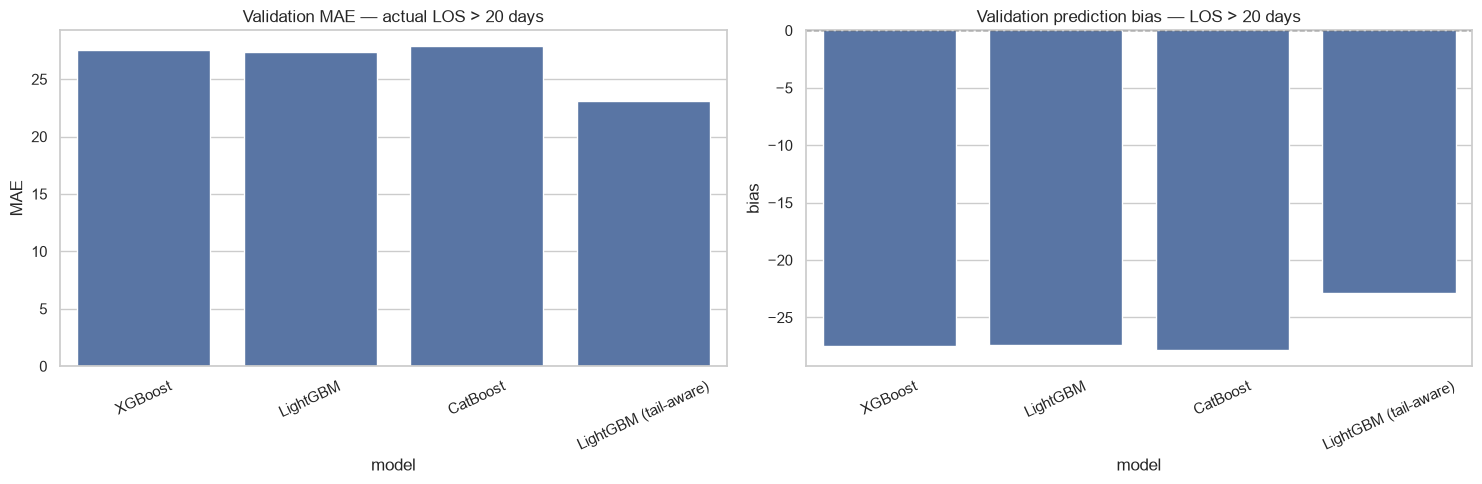

Negative bias means systematic underprediction. Compare against all-stay RMSE before selecting a model.


In [ ]:
# 23D. Long-stay validation metrics and error visualizations for new models
longstay_rows = []
for fs in BOOST_SETS:
    for name in ['XGBoost', 'LightGBM', 'CatBoost', 'LightGBM (tail-aware)']:
        key = (fs, name)
        p = np.asarray(val_pred[key])[val_eval_pos]
        y = y_val[val_eval_pos]
        for label, mask in [
            ('1–2', (y >= 1) & (y <= 2)),
            ('3–5', (y > 2) & (y <= 5)),
            ('6–10', (y > 5) & (y <= 10)),
            ('11–20', (y > 10) & (y <= 20)),
            ('21+', y > 20)
        ]:
            if not mask.any():
                continue
            longstay_rows.append({
                'feature_set': fs, 'model': name, 'LOS_bucket': label,
                'n': int(mask.sum()), 'MAE': float(np.mean(np.abs(p[mask]-y[mask]))),
                'bias': float(np.mean(p[mask]-y[mask])),
                'RMSE': float(np.sqrt(np.mean((p[mask]-y[mask])**2)))
            })
longstay_df = pd.DataFrame(longstay_rows)
display(longstay_df.round(2))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=longstay_df[longstay_df.LOS_bucket == '21+'],
            x='model', y='MAE', ax=axes[0])
axes[0].set_title('Validation MAE — actual LOS > 20 days')
sns.barplot(data=longstay_df[longstay_df.LOS_bucket == '21+'],
            x='model', y='bias', ax=axes[1])
axes[1].axhline(0, ls='--', color='black', lw=1)
axes[1].set_title('Validation prediction bias — LOS > 20 days')
for ax in axes:
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()
print('Negative bias means systematic underprediction. Compare against all-stay RMSE before selecting a model.')


#### Results: error by actual-LOS bucket (validation)

| Actual LOS | n | XGBoost MAE | LightGBM MAE | CatBoost MAE | Tail-aware LightGBM MAE | Typical bias (standard models) |
|---|---:|---:|---:|---:|---:|---:|
| 1 to 2 days | 21,650 | 3.00 | 2.98 | 3.02 | 4.92 | **+3.0** (over-predict) |
| 3 to 5 days | 20,119 | 1.86 | 1.86 | 1.81 | 3.90 | +1.5 |
| 6 to 10 days | 8,668 | 2.17 | 2.22 | 2.09 | 3.34 | -1.2 to -1.3 |
| 11 to 20 days | 3,911 | 7.39 | 7.38 | 7.49 | 5.60 | -7.2 to -7.4 |
| 21+ days | 1,906 | 27.53 | 27.41 | 27.85 | 23.10 | **-27.4 to -27.9** |

**Pattern.** Predictions are pulled toward the average: short stays are overestimated, long stays underestimated. This is the typical behavior of a regression model when the available features explain little of the variance.

**Tail-aware trade-off.** Weighting long stays improves the 11 to 20 day and 21+ day buckets, but errors rise in every other bucket (1 to 2 day MAE goes from 2.98 to 4.92) and the 6 to 10 day bias flips from -1.2 to +1.6.

> **Takeaway:** up-weighting the tail does not fix the underlying information gap; it only moves error from rare long stays to common short ones.

,feature_set,model,MAE,RMSE,R2,Bias,MAE_21plus,Bias_21plus,N_21plus,selection_score,fit_minutes
0,A,HistGB Poisson,3.58,7.33,0.09,0.06,27.45,-27.41,1906,10.07,0.00
1,A,LightGBM,3.59,7.34,0.09,0.05,27.41,-27.39,1906,10.08,0.00
2,A,XGBoost,3.60,7.33,0.09,0.05,27.53,-27.50,1906,10.08,0.00
3,A,CatBoost,3.60,7.33,0.09,0.03,27.85,-27.85,1906,10.12,0.60
4,A,RBF-SVR,3.62,7.43,0.07,-0.00,28.77,-28.71,1906,10.31,3.10
5,A,Linear Regression (raw target),3.72,7.46,0.06,0.06,28.73,-28.73,1906,10.33,0.00
6,A,Linear Regression,3.67,7.48,0.05,-0.02,29.22,-29.21,1906,10.40,0.00
7,A,Ridge,3.67,7.48,0.05,-0.02,29.23,-29.22,1906,10.40,0.10
8,A,Elastic Net,3.67,7.48,0.05,-0.02,29.27,-29.27,1906,10.41,0.30
9,A,HistGB Poisson (tail-aware),4.96,8.09,-0.11,2.41,23.18,-22.92,1906,10.41,0.00


Validation mean-only baseline: MAE 3.981, RMSE 7.689


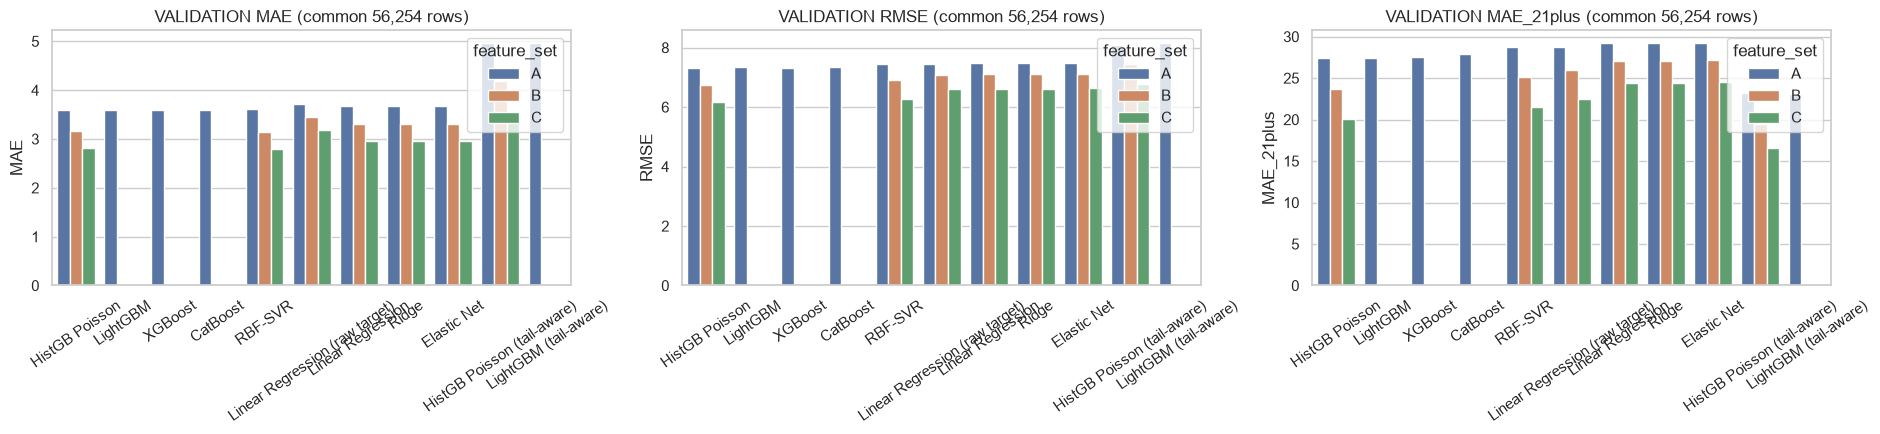

In [ ]:
# 24. VALIDATION model comparison; absolutely no use of the test targets.
res = pd.DataFrame(rows).sort_values(['feature_set', 'selection_score']).reset_index(drop=True)
display(res.round(3))
base = score(y_val[val_eval_pos], np.full(len(val_eval_pos), y_tr.mean()))
print(f'Validation mean-only baseline: MAE {base["MAE"]:.3f}, RMSE {base["RMSE"]:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAE_21plus']):
    sns.barplot(data=res, x='model', y=metric, hue='feature_set', ax=ax)
    ax.set_title(f'VALIDATION {metric} (common {len(val_eval_pos):,} rows)')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()


#### Results: validation leaderboard

**Feature set A, ranked by selection score** (lower is better; baseline = predict the training mean):

| Rank | Model | MAE | RMSE | R² | MAE (21+) | Selection score |
|---:|---|---:|---:|---:|---:|---:|
| 1 | **HistGB Poisson** | 3.58 | 7.33 | 0.09 | 27.45 | **10.07** |
| 2 | LightGBM | 3.59 | 7.34 | 0.09 | 27.41 | 10.08 |
| 3 | XGBoost | 3.60 | 7.33 | 0.09 | 27.53 | 10.08 |
| 4 | CatBoost | 3.60 | 7.33 | 0.09 | 27.85 | 10.12 |
| 5 | RBF-SVR | 3.62 | 7.43 | 0.07 | 28.77 | 10.31 |
| 6 | Linear Regression (raw target) | 3.72 | 7.46 | 0.06 | 28.73 | 10.33 |
| 7 to 9 | Linear / Ridge / Elastic Net | 3.67 | 7.48 | 0.05 | 29.2 to 29.3 | 10.40 to 10.41 |
| 10 to 11 | Tail-aware HistGB / LightGBM | 4.96 to 4.97 | 8.09 to 8.17 | -0.11 to -0.13 | 23.1 to 23.2 | 10.41 to 10.48 |
| | *Mean-only baseline* | *3.98* | *7.69* | *about 0* | | |

**How much does extra information help? (best model per feature set)**

| Set | Best model (selection score) | MAE | RMSE | R² |
|---|---|---:|---:|---:|
| A (admission-time) | HistGB Poisson | 3.58 | 7.33 | 0.09 |
| B (+ diagnosis group) | HistGB Poisson | 3.17 | 6.75 | 0.23 |
| C (+ severity and mortality) | HistGB Poisson | 2.81 | 6.16 | 0.36 |

**Interpretation**

- The top four Set A models are **practically tied** (selection scores 10.07 to 10.12). HistGB Poisson wins narrowly and is also the fastest to fit.
- The best Set A model beats the mean-only baseline by about **10% on MAE** (3.98 to 3.58) and about **5% on RMSE** (7.69 to 7.33).
- Tail-aware variants rank last because their higher overall error outweighs the long-stay gain under the selection rule.
- Diagnosis and severity information would lift R² from 0.09 to 0.23 and 0.36, but those fields are discharge-coded, so this is a benchmark, not a deployable result.
- The standard Set A models have near-zero overall bias (-0.02 to +0.06 days); their errors are concentrated in the tails. The tail-aware variants over-predict by about +2.4 days on average.
- XGBoost, LightGBM and CatBoost were run on Set A only; Sets B and C compare HistGB, RBF-SVR and the linear models.

<a id="sec8"></a>
## 8. Final evaluation on the held-out test set

The model and feature set are frozen using validation results only. The test set is opened **once** for final reporting.

Selected on VALIDATION: HistGB Poisson, feature set A
FINAL untouched-test metrics: {'MAE': 3.608841424380331, 'RMSE': 7.514398329485714, 'R2': 0.09243509589925347, 'Bias': -0.011863148946853348}
FINAL test long-stay metrics: {'MAE_21plus': 28.46783218530486, 'Bias_21plus': -28.44225138402263, 'N_21plus': 2399}
FINAL uncensored-only test metrics: {'MAE': 3.5258548339196105, 'RMSE': 6.850026372214147, 'R2': 0.10022310052991157, 'Bias': 0.07388782764152073}


,n,MAE,bias
bucket,,,
1-2,27063,2.95,2.95
3-5,25148,1.82,1.45
6-10,10805,2.18,-1.28
11-20,4903,7.41,-7.18
21+,2399,28.47,-28.44


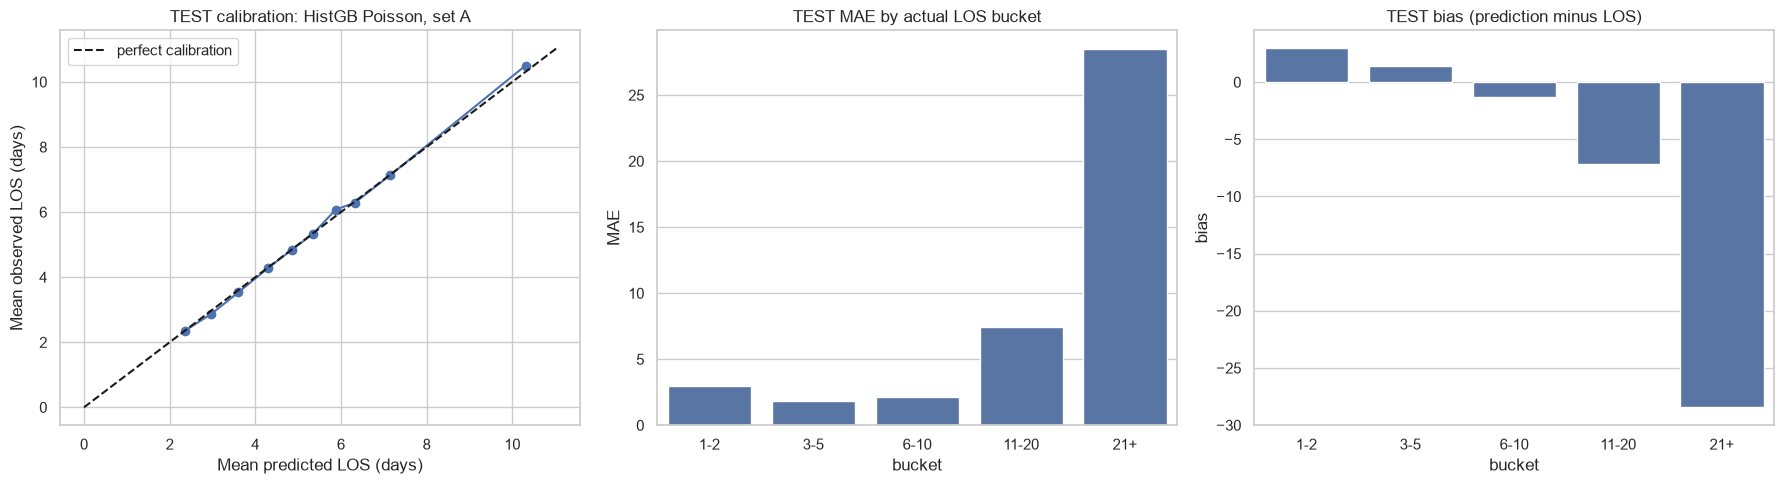

In [ ]:
# 25. Freeze selection using VALIDATION, then open TEST once for final reporting.
# A = admission-time evaluation. B/C = retrospective benchmarks only.
FINAL_SET = 'A'
assert FINAL_SET == 'A', 'Do not present discharge-coded B/C as admission-time predictors.'
cand = res[res.feature_set == FINAL_SET]
FINAL_MODEL = str(cand.sort_values('selection_score').iloc[0]['model'])
print(f'Selected on VALIDATION: {FINAL_MODEL}, feature set {FINAL_SET}')

cats, nums = FEATURE_SETS[FINAL_SET]
model = fitted[(FINAL_SET, FINAL_MODEL)]
if FINAL_MODEL.startswith('HistGB'):
    X_test_final = tree_preps[FINAL_SET].transform(df.loc[test_idx, cats + nums])
    pred = np.maximum(model.predict(X_test_final), 1)
elif FINAL_MODEL.startswith(('XGBoost', 'LightGBM')):
    X_test_final = boost_preps[FINAL_SET].transform(df.loc[test_idx, cats + nums])
    pred = np.maximum(model.predict(X_test_final), 1)
elif FINAL_MODEL.startswith('CatBoost'):
    X_test_final = catboost_frame(df.loc[test_idx], FINAL_SET)
    pred = np.maximum(model.predict(X_test_final), 1)
else:
    X_test_final = M[FINAL_SET]['prep'].transform(df.loc[test_idx, cats + nums])
    if FINAL_MODEL == 'RBF-SVR':
        raw_prediction = svr_predict(model, sparse.csr_matrix(X_test_final))
    else:
        raw_prediction = model.predict(X_test_final)
    if FINAL_MODEL == 'Linear Regression (raw target)':
        pred = np.maximum(raw_prediction, 1)
    else:
        pred = back_transform(raw_prediction, smearing[(FINAL_SET, FINAL_MODEL)])

y_ok = df.loc[test_idx, 'length_of_stay'].to_numpy(dtype=float)
p_ok = pred
ok = np.isfinite(p_ok)
print('FINAL untouched-test metrics:', score(y_ok[ok], p_ok[ok]))
print('FINAL test long-stay metrics:', tail_score(y_ok[ok], p_ok[ok]))

# Top-coded values are lower bounds, not observed exact durations.
uncensored = ~df.loc[test_idx, 'los_censored'].fillna(False).to_numpy(dtype=bool)
valid_uncensored = ok & uncensored
print('FINAL uncensored-only test metrics:',
      score(y_ok[valid_uncensored], p_ok[valid_uncensored]))

# Diagnostic plots are TEST diagnostics, not tools for additional model selection.
cal = pd.DataFrame({'y': y_ok[ok], 'p': p_ok[ok]})
cal['bin'] = pd.qcut(cal['p'], 10, duplicates='drop')
cal_t = cal.groupby('bin', observed=True).agg(pred_mean=('p', 'mean'),
                                              actual_mean=('y', 'mean'))
cal['bucket'] = pd.cut(cal['y'], [0, 2, 5, 10, 20, np.inf],
                       labels=['1-2', '3-5', '6-10', '11-20', '21+'])
cal['abs_err'] = (cal['p'] - cal['y']).abs()
cal['err'] = cal['p'] - cal['y']
bucket_t = cal.groupby('bucket', observed=True).agg(
    n=('y', 'size'), MAE=('abs_err', 'mean'), bias=('err', 'mean'))
display(bucket_t.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(cal_t['pred_mean'], cal_t['actual_mean'], 'o-')
lim = [0, max(cal_t.max().max(), 1) * 1.05]
axes[0].plot(lim, lim, 'k--', label='perfect calibration')
axes[0].set(xlabel='Mean predicted LOS (days)', ylabel='Mean observed LOS (days)',
            title=f'TEST calibration: {FINAL_MODEL}, set {FINAL_SET}')
axes[0].legend()
sns.barplot(data=bucket_t.reset_index(), x='bucket', y='MAE', ax=axes[1])
axes[1].set_title('TEST MAE by actual LOS bucket')
sns.barplot(data=bucket_t.reset_index(), x='bucket', y='bias', ax=axes[2])
axes[2].set_title('TEST bias (prediction minus LOS)')
plt.tight_layout()
plt.show()


#### Results: final test performance

**Selected model:** HistGB Poisson, feature set A (chosen on validation).

| Test subset | MAE | RMSE | R² | Bias |
|---|---:|---:|---:|---:|
| All 70,318 discharges | **3.61** | **7.51** | **0.09** | -0.01 |
| Excluding top-coded (120+) stays | 3.53 | 6.85 | 0.10 | +0.07 |
| Stays over 20 days only (n = 2,399) | 28.47 | n/a | n/a | -28.44 |

**Error by actual-LOS bucket (test)**

| Actual LOS | n | MAE | Bias |
|---|---:|---:|---:|
| 1 to 2 days | 27,063 | 2.95 | +2.95 |
| 3 to 5 days | 25,148 | 1.82 | +1.45 |
| 6 to 10 days | 10,805 | 2.18 | -1.28 |
| 11 to 20 days | 4,903 | 7.41 | -7.18 |
| 21+ days | 2,399 | 28.47 | -28.44 |

**Plots**

- **Calibration:** across prediction deciles (mean predicted LOS roughly 2.3 to 10.3 days) observed means sit on or very close to the diagonal, so the model is well calibrated *on average*.
- **MAE by bucket:** error is small for 1 to 10 day stays and rises sharply beyond 10 days.
- **Bias by bucket:** a clean slope from over-prediction of short stays to heavy under-prediction of long stays.

**Interpretation**

- Test metrics are close to validation (MAE 3.61 vs. 3.58; RMSE 7.51 vs. 7.33), which suggests little over-fitting to the validation data.
- Dropping the small number of top-coded stays lowers test RMSE from 7.51 to 6.85, which shows how few extreme stays dominate the squared-error metric.
- The model is good at predicting *typical* stays and the *average* stay for a group, but it cannot identify individual patients who will stay unusually long using admission-time fields alone.

> **Takeaway:** use this model for group-level planning and average-LOS estimates, not for flagging individual long-stay patients.

<a id="sec9"></a>
## 9. Model interpretation

Two complementary views: linear-model coefficients (global, signed) and SHAP values for a tree model (global and per-patient). Both describe *associations*, not causal effects.

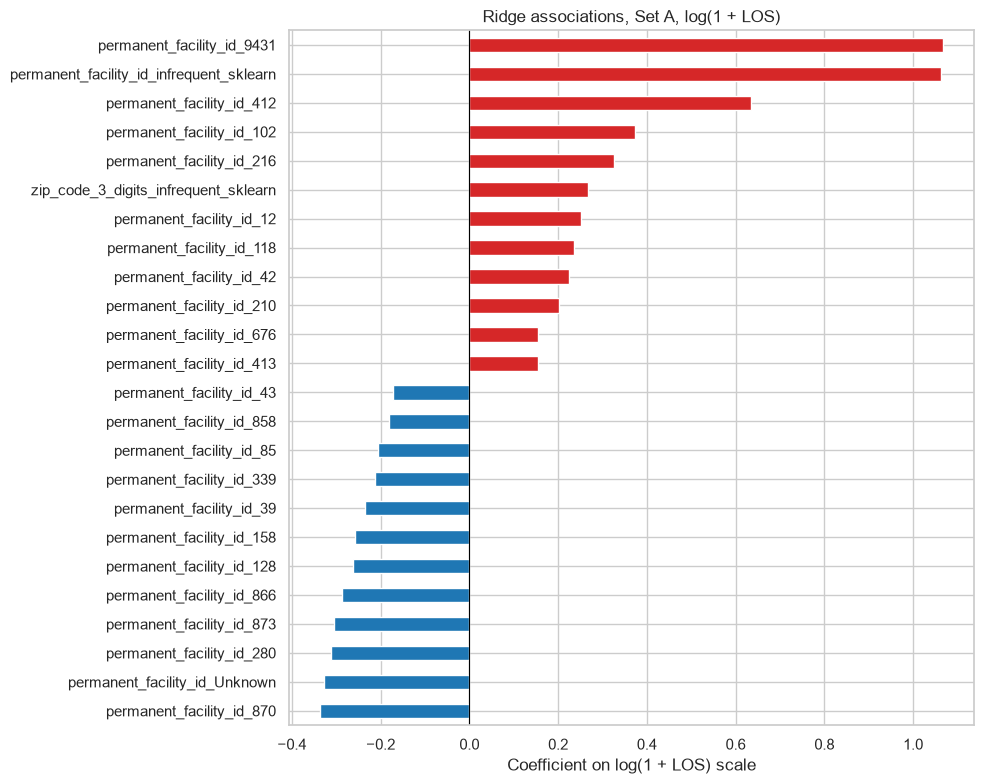

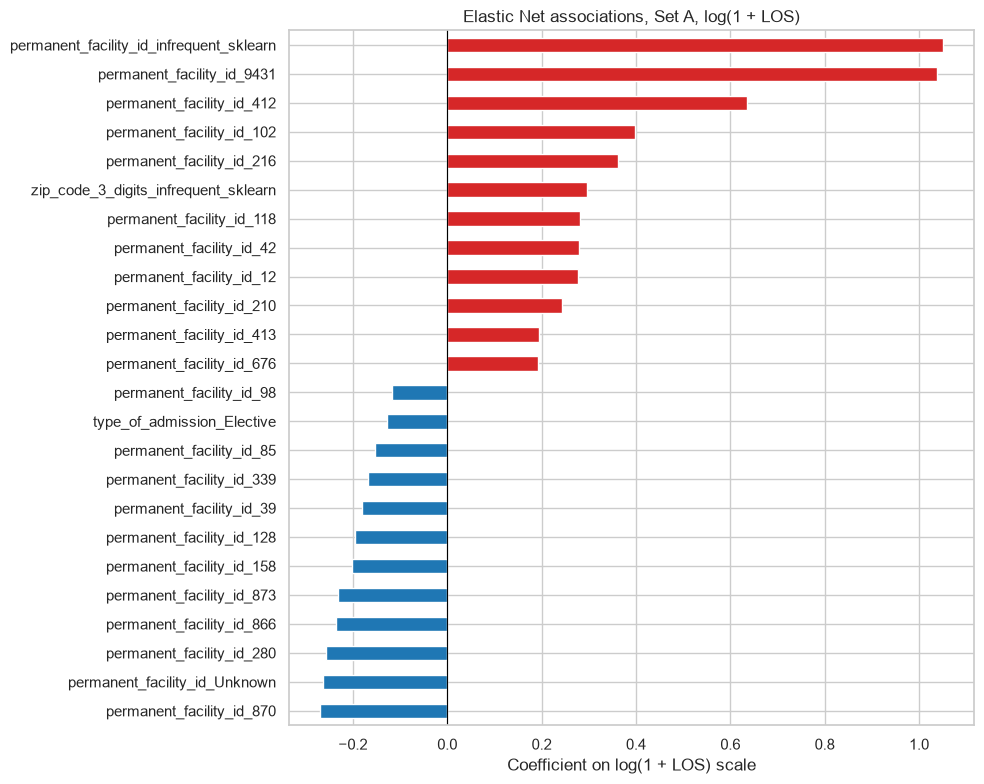

In [ ]:
# 26. Interpretation: Ridge / Elastic Net coefficients (fitted encoder names)
# Coefficients describe model associations, NOT causal effects.
def top_coefs(fs, model_name, n=12):
    mdl = fitted[(fs, model_name)]
    cat_features, num_features = FEATURE_SETS[fs]
    fitted_cat_pipeline = M[fs]['prep'].named_transformers_['cat']
    enc = fitted_cat_pipeline.named_steps['encode']
    categorical_names = enc.get_feature_names_out(cat_features)
    feature_names = np.concatenate([categorical_names, np.asarray(num_features, dtype=str)])
    coefficients = np.asarray(mdl.coef_).ravel()
    if len(feature_names) != len(coefficients):
        raise ValueError(f'Names ({len(feature_names)}) != coefficients ({len(coefficients)}).')
    s = pd.Series(coefficients, index=feature_names).sort_values()
    return pd.concat([s.head(n), s.tail(n)])

for model_name in ['Ridge', 'Elastic Net']:
    if (FINAL_SET, model_name) not in fitted:
        continue
    s = top_coefs(FINAL_SET, model_name)
    plt.figure(figsize=(10, 8))
    s.plot.barh(color=np.where(s > 0, 'tab:red', 'tab:blue'))
    plt.axvline(0, color='black', lw=0.8)
    plt.title(f'{model_name} associations, Set {FINAL_SET}, log(1 + LOS)')
    plt.xlabel('Coefficient on log(1 + LOS) scale')
    plt.tight_layout()
    plt.show()


#### Results: Ridge and Elastic Net coefficients (Set A, log scale)

- Both charts are dominated by **facility-ID dummies**. The largest positive coefficients are facility 9431 and the grouped rare-facility level (both about +1.05 to +1.07), then facility 412 (about +0.63), 102 and 216 (about +0.3 to +0.4).
- The largest negative coefficients reach about -0.33 (Ridge) and -0.27 (Elastic Net), for example facilities 870, 280, 873 and the `Unknown` facility group. Elastic Net also keeps `type_of_admission_Elective` (about -0.12) among its strongest negative terms.
- A coefficient of +1.07 on the log(1 + LOS) scale means roughly **2.9 times** the expected (1 + LOS) for that facility, other fields equal.
- Rare zip-code prefixes pooled by the encoder (`infrequent`) also show a positive effect.

> **Takeaway:** in the linear models, *where* a patient is admitted outweighs demographics. Coefficients for rare facilities are estimated from few rows and should be read cautiously.

### SHAP explanations for a tuned nonlinear model

SHAP uses a fixed sample of **validation rows**. It describes model contributions rather than causal effects. This section explains the best **new tree candidate** on validation, which may differ from the final overall selected model. For ordinal-coded models, the categorical encodings are identifiers, not meaningful numerical scales.

SHAP interpretation: LightGBM | 200 validation discharges


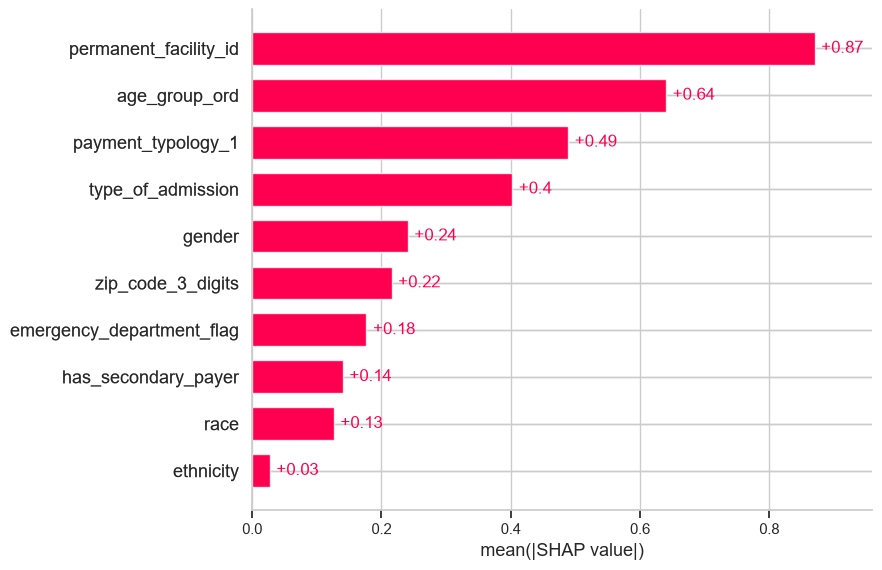

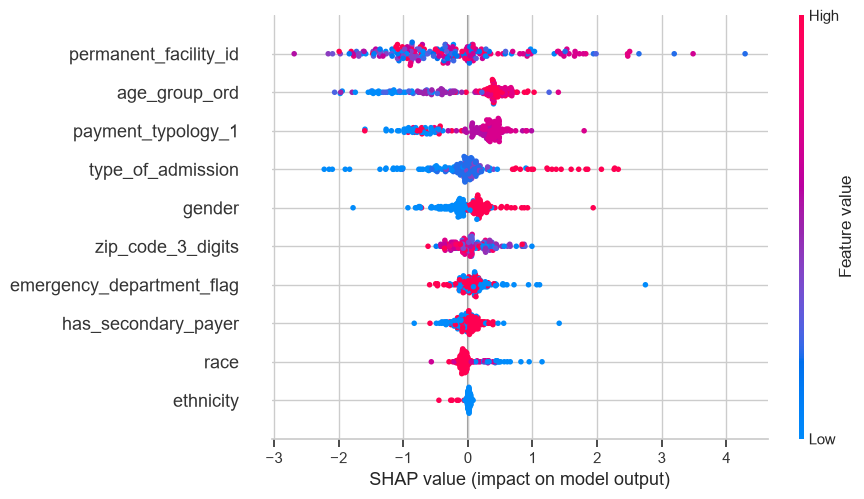

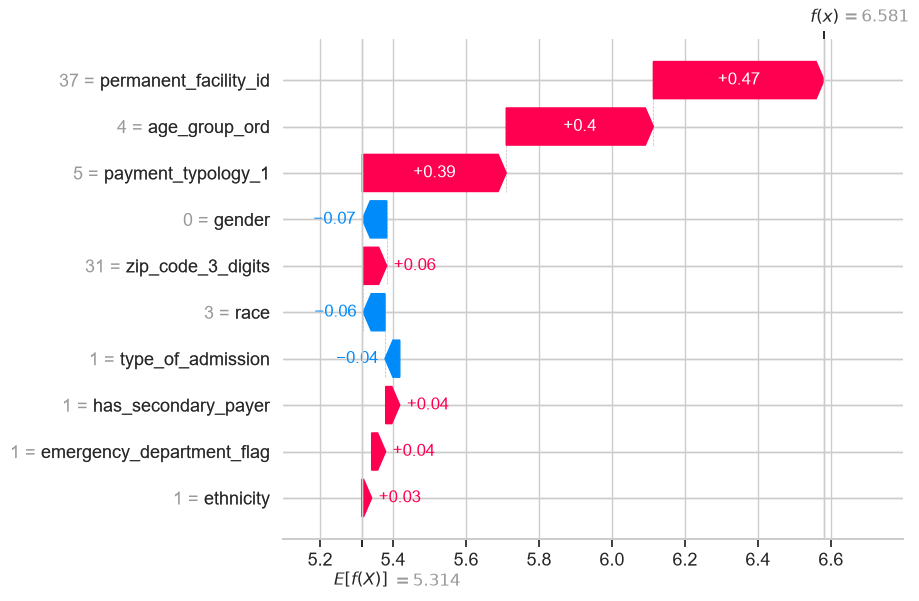

SHAP units: predicted LOS days. These are predictive associations, not causal effects.


In [ ]:
# 26A. SHAP: validation-only explanations of best new nonlinear candidate
import shap

shap_candidates = res[(res.feature_set == 'A') &
                      (res.model.isin(['XGBoost', 'LightGBM', 'CatBoost',
                                      'LightGBM (tail-aware)']))]
shap_model_name = str(shap_candidates.sort_values('selection_score').iloc[0]['model'])
shap_model = fitted[('A', shap_model_name)]
shap_rng = np.random.default_rng(42)
shap_pos = np.sort(shap_rng.choice(len(val_idx), min(200, len(val_idx)), replace=False))

if shap_model_name.startswith('CatBoost'):
    shap_X = catboost_data['A'][1].iloc[shap_pos]
    # TreeExplainer for categorical models may require a Pool for reliability.
    from catboost import Pool
    cat_cols, _ = FEATURE_SETS['A']
    shap_values_raw = shap_model.get_feature_importance(
        Pool(shap_X, cat_features=cat_cols), type='ShapValues')
    shap_values = np.asarray(shap_values_raw[:, :-1])
    shap_base = shap_values_raw[:, -1]
    shap_display = shap_X.copy()
else:
    shap_X = boost_data['A'][1][shap_pos]
    shap_display = pd.DataFrame(shap_X,
        columns=FEATURE_SETS['A'][0] + FEATURE_SETS['A'][1])
    explainer = shap.TreeExplainer(shap_model)
    shap_values = np.asarray(explainer.shap_values(shap_X))
    shap_base = np.asarray(explainer.expected_value).ravel()[0]
    shap_base = np.repeat(shap_base, len(shap_X))

print(f'SHAP interpretation: {shap_model_name} | {len(shap_pos)} validation discharges')
shap_exp = shap.Explanation(values=shap_values, base_values=shap_base,
                            data=shap_display.to_numpy(),
                            feature_names=list(shap_display.columns))
shap.plots.bar(shap_exp, max_display=15, show=True)
shap.plots.beeswarm(shap_exp, max_display=15, show=True)
shap.plots.waterfall(shap_exp[0], max_display=12, show=True)
print('SHAP units: predicted LOS days. These are predictive associations, not causal effects.')


#### Results: SHAP explanations (LightGBM, 200 validation discharges)

**Global importance (mean absolute SHAP value, in days of predicted LOS)**

| Rank | Feature | Mean abs. SHAP |
|---:|---|---:|
| 1 | `permanent_facility_id` | **0.87** |
| 2 | `age_group_ord` | 0.64 |
| 3 | `payment_typology_1` | 0.49 |
| 4 | `type_of_admission` | 0.40 |
| 5 | `gender` | 0.24 |
| 6 | `zip_code_3_digits` | 0.22 |
| 7 | `emergency_department_flag` | 0.18 |
| 8 | `has_secondary_payer` | 0.14 |
| 9 | `race` | 0.13 |
| 10 | `ethnicity` | 0.03 |

**Three plots are produced:** a bar chart (the ranking above), a beeswarm (direction and spread of each feature's effect across patients) and a waterfall (how one patient's prediction is built from the baseline).

**Interpretation**

- **Facility, age, payer and admission type** account for most of the model's signal, matching the EDA in section 5.
- Even the top feature shifts a typical prediction by less than a day, consistent with the modest R².
- Race and ethnicity contribute little. Their inclusion should still be reviewed for fairness before any operational use.
- SHAP is computed on only 200 rows, and categorical codes are IDs, not scales, so treat the ranking as indicative.

<a id="sec10"></a>
## 10. Bed-day planning and optimization scenario

Translate LOS predictions into bed-days, check how accurate those totals are by service line, then run an illustrative integer program.

In [ ]:
# 27. Retrospective bed-day planning illustration on HELD-OUT TEST discharges.
# Category (APR MDC) is an ANALYSIS grouping, not an admission-time model predictor.
# This is not a prospective volume forecast or proof of future bed availability.
mdc_test = df.loc[test_idx, 'apr_mdc_description'].to_numpy()
calc = pd.DataFrame({'category': mdc_test[ok], 'actual': y_ok[ok], 'pred': p_ok[ok]})
svc = calc.groupby('category', observed=True).agg(
    n_eval=('actual', 'size'), actual_mean_los=('actual', 'mean'),
    pred_mean_los=('pred', 'mean'),
    actual_bed_days=('actual', 'sum'), pred_bed_days=('pred', 'sum'))
svc['los_bias_%'] = (svc['pred_mean_los'] / svc['actual_mean_los'] - 1) * 100
svc['bed_day_error_%'] = (svc['pred_bed_days'] / svc['actual_bed_days'] - 1) * 100
svc = svc.sort_values('actual_bed_days', ascending=False)
display(svc.round(2))

tot_err = svc['pred_bed_days'].sum() / svc['actual_bed_days'].sum() - 1
print(f'HELD-OUT test discharge bed-day error: {tot_err * 100:+.2f}%')
print('Top-coded 120+ stays contribute lower-bound observed bed-days.')


,n_eval,actual_mean_los,pred_mean_los,actual_bed_days,pred_bed_days,los_bias_%,bed_day_error_%
category,,,,,,,
Diseases and Disorders of the Circulatory System,8223,5.16,5.95,"42,403.00","48,936.80",15.41,15.41
"Infectious and Parasitic Diseases, Systemic or Unspecified Sites",4591,8.32,5.71,"38,204.00","26,217.21",-31.38,-31.38
Diseases and Disorders of the Respiratory System,6470,5.31,5.52,"34,333.00","35,732.54",4.08,4.08
Diseases and Disorders of the Musculoskeletal System and Conn Tissue,7807,4.15,4.75,"32,413.00","37,113.96",14.50,14.50
Mental Diseases and Disorders,3471,9.33,7.06,"32,377.00","24,493.86",-24.35,-24.35
Diseases and Disorders of the Digestive System,5916,5.20,5.38,"30,771.00","31,798.80",3.34,3.34
Newborns and Other Neonates with Conditions Originating in the Perinatal Period,6755,3.75,3.82,"25,349.00","25,777.69",1.69,1.69
Diseases and Disorders of the Nervous System,4171,5.71,5.90,"23,821.00","24,591.18",3.23,3.23
"Pregnancy, Childbirth and the Puerperium",7112,2.68,3.09,"19,078.00","21,987.91",15.25,15.25


HELD-OUT test discharge bed-day error: -0.22%
Top-coded 120+ stays contribute lower-bound observed bed-days.


#### Results: retrospective bed-day accuracy by service line (test set)

**Overall, the model is unbiased: predicted total bed-days differ from actual by only -0.22%.** By service line the picture is mixed:

| Service line | Actual mean LOS | Predicted mean LOS | Bed-day error |
|---|---:|---:|---:|
| Circulatory | 5.16 | 5.95 | **+15.4%** |
| Infectious / parasitic | 8.32 | 5.71 | **-31.4%** |
| Respiratory | 5.31 | 5.52 | +4.1% |
| Musculoskeletal | 4.15 | 4.75 | +14.5% |
| Mental diseases | 9.33 | 7.06 | **-24.4%** |
| Digestive | 5.20 | 5.38 | +3.3% |
| Newborns / neonates | 3.75 | 3.82 | +1.7% |
| Nervous system | 5.71 | 5.90 | +3.2% |
| Pregnancy / childbirth | 2.68 | 3.09 | +15.3% |
| Alcohol / drug use | 9.30 | 8.74 | -6.1% |
| Rehabilitation / aftercare | 12.63 | 7.74 | **-38.7%** |

*Smaller categories show larger swings (for example male reproductive +123.5% with n = 251, eye +85.2% with n = 72), which partly reflects small samples.*

**Why:** the admission-time model has no diagnosis information, so it shrinks every service line toward the overall mean of about 5 days. Long-stay lines (rehabilitation, mental health, infectious disease, hematologic malignancies, trauma, burns) are **underpredicted by 24 to 39%**, while shorter-stay lines (pregnancy, musculoskeletal, circulatory, endocrine, ENT) are **overpredicted by 14 to 32%**.

> **Takeaway:** system-wide totals are reliable, service-line totals are not. A service-line capacity plan would need diagnosis-level information (Set B-type features) or a bias correction.

### Hospital bed-capacity optimization — **illustrative MILP scenario**

The dataset does **not** provide verified staffed-bed capacities, staffing constraints, arrivals over time, or future admission forecasts. Therefore, this is an **explicit scenario**, not a validated real-world hospital optimization. The code uses observed 2015 discharge counts and held-out mean LOS predictions to estimate a **reference annual bed-day demand** per hospital. It assumes a global number of allocatable staffed beds, a target occupancy, per-hospital minimum allocations, and priority weights. These values must be replaced with genuine operational inputs before any deployment. The optimization minimizes **weighted unmet demand** subject to a shared bed budget, with integer bed allocations.

In [ ]:
# 28. Build hospital-level reference demands from modeled LOS and historical volumes
# Do not confuse observed discharge volume with a forecast of future admissions.
from scipy.optimize import milp, Bounds, LinearConstraint

hosp_test = df.loc[test_idx, 'facility_name'].astype('string').fillna('Unknown').to_numpy()
reference = pd.DataFrame({
    'hospital': hosp_test[ok],
    'pred_los': p_ok[ok],
    'actual_los_lower_bound': y_ok[ok]
})
hospital_reference = reference.groupby('hospital').agg(
    evaluated_discharges=('pred_los', 'size'),
    predicted_mean_los=('pred_los', 'mean'),
    observed_mean_los_lb=('actual_los_lower_bound', 'mean')
)
# Entire 2015 recorded discharge count — reference volume, NOT prospective volume.
annual_volume = (df['facility_name'].astype('string').fillna('Unknown')
                 .value_counts(dropna=False).rename('annual_reference_discharges'))
hospital_reference = hospital_reference.join(annual_volume, how='left')
hospital_reference = hospital_reference.dropna(subset=['predicted_mean_los',
                                                       'annual_reference_discharges'])
hospital_reference['reference_bed_days'] = (
    hospital_reference['predicted_mean_los'] *
    hospital_reference['annual_reference_discharges'])

# Explicit scenario assumptions (not observed SPARCS capacity data):
DAYS_PER_YEAR = 365
TARGET_OCCUPANCY = 0.85          # assumed usable occupancy threshold
BUDGET_FRACTION = 0.90          # scenario: 90% of reference beds needed
# A minimum commitment of 40% of each hospital's reference requirement.
MIN_ALLOCATION_FRACTION = 0.40
needed_beds = np.ceil(hospital_reference.reference_bed_days /
                      (DAYS_PER_YEAR * TARGET_OCCUPANCY)).astype(int)
hospital_reference['reference_beds_needed'] = needed_beds
hospital_reference['minimum_beds'] = np.floor(
    MIN_ALLOCATION_FRACTION * needed_beds).astype(int)
TOTAL_BEDS_AVAILABLE = max(
    int(hospital_reference.minimum_beds.sum()),
    int(np.floor(BUDGET_FRACTION * needed_beds.sum()))
)
# Weights represent an illustrative priority for higher LOS service pressure.
# Replace with clinically/operationally approved weights for a real application.
hospital_reference['priority_weight'] = np.clip(
    hospital_reference['predicted_mean_los'] /
    hospital_reference['predicted_mean_los'].median(), 0.8, 1.5)

print(f'Hospitals: {len(hospital_reference)} | reference beds needed: {needed_beds.sum():,}')
print(f'Scenario shared staffed-bed budget: {TOTAL_BEDS_AVAILABLE:,}')
print('Assumed occupancy:', TARGET_OCCUPANCY)
display(hospital_reference.head().round(2))


Hospitals: 58 | reference beds needed: 6,055
Scenario shared staffed-bed budget: 5,449
Assumed occupancy: 0.85


,evaluated_discharges,predicted_mean_los,observed_mean_los_lb,annual_reference_discharges,reference_bed_days,reference_beds_needed,minimum_beds,priority_weight
hospital,,,,,,,,
Arnot Ogden Medical Center,2206,4.60,4.76,11024,"50,679.73",164,65,0.96
Auburn Community Hospital,1081,4.38,4.28,5338,"23,357.09",76,30,0.91
Bertrand Chaffee Hospital,212,3.36,3.43,981,"3,293.19",11,4,0.80
Brooks Memorial Hospital,489,3.45,3.33,2461,"8,495.21",28,11,0.80
Buffalo General Medical Center,4523,5.84,5.79,22872,"133,540.53",431,172,1.22


#### Results: hospital reference demand and scenario inputs

| Quantity | Value |
|---|---|
| Hospitals in the model | 58 |
| Reference bed requirement (85% target occupancy) | **6,055 beds** |
| Shared staffed-bed budget (90% of requirement) | **5,449 beds** |
| Minimum per hospital | 40% of its own requirement |
| Priority weights | Predicted mean LOS divided by the median hospital, clipped to 0.8 to 1.5 |

**Reference bed-days** = predicted mean LOS (test set) x 2015 annual discharges, converted to beds with `beds = bed-days / (365 x 0.85)`.

Example rows:

| Hospital | Predicted mean LOS | Observed mean LOS | Annual discharges | Beds needed | Minimum beds | Weight |
|---|---:|---:|---:|---:|---:|---:|
| Buffalo General Medical Center | 5.84 | 5.79 | 22,872 | 431 | 172 | 1.22 |
| Arnot Ogden Medical Center | 4.60 | 4.76 | 11,024 | 164 | 65 | 0.96 |
| Auburn Community Hospital | 4.38 | 4.28 | 5,338 | 76 | 30 | 0.91 |
| Brooks Memorial Hospital | 3.45 | 3.33 | 2,461 | 28 | 11 | 0.80 |
| Bertrand Chaffee Hospital | 3.36 | 3.43 | 981 | 11 | 4 | 0.80 |

> **Takeaway:** hospital-level predicted LOS is close to observed LOS (within roughly 0.4 days in the rows shown here and below), so the demand inputs are reasonable. The **capacities, occupancy, budget and weights are assumptions**, not SPARCS data.

Illustrative optimization scenario: {'beds_allocated': 5449, 'beds_available': 5449, 'reference_bed_days': 1869351, 'unmet_bed_days': 179289, 'demand_coverage_%': np.float64(90.41)}


,evaluated_discharges,predicted_mean_los,observed_mean_los_lb,annual_reference_discharges,reference_bed_days,reference_beds_needed,minimum_beds,priority_weight,allocated_beds,unmet_bed_days,met_demand_pct
hospital,,,,,,,,,,,
Millard Fillmore Suburban Hospital,3378,4.12,3.88,16743,"68,985.17",223,89,0.86,89,"41,372.92",40.03
Our Lady of Lourdes Memorial Hospital Inc,2225,4.10,4.00,10877,"44,579.02",144,57,0.85,57,"26,894.77",39.67
Olean General Hospital,1222,4.19,4.33,5906,"24,764.03",80,32,0.87,32,"14,836.03",40.09
F F Thompson Hospital,1143,4.00,4.04,5738,"22,941.09",74,29,0.83,29,"13,943.84",39.22
Newark-Wayne Community Hospital,1162,3.91,4.07,5643,"22,059.37",72,28,0.81,28,"13,372.37",39.38
Highland Hospital,3745,4.25,4.30,18778,"79,775.95",258,103,0.88,221,"11,210.70",85.95
Corning Hospital,960,3.25,3.31,4721,"15,347.57",50,20,0.80,20,"9,142.57",40.43
Cortland Regional Medical Center Inc,822,3.77,4.16,3907,"14,747.50",48,19,0.80,19,"8,852.75",39.97
United Memorial Medical Center North Street Campus,793,3.31,3.27,3952,"13,087.92",43,17,0.80,17,"7,813.67",40.30


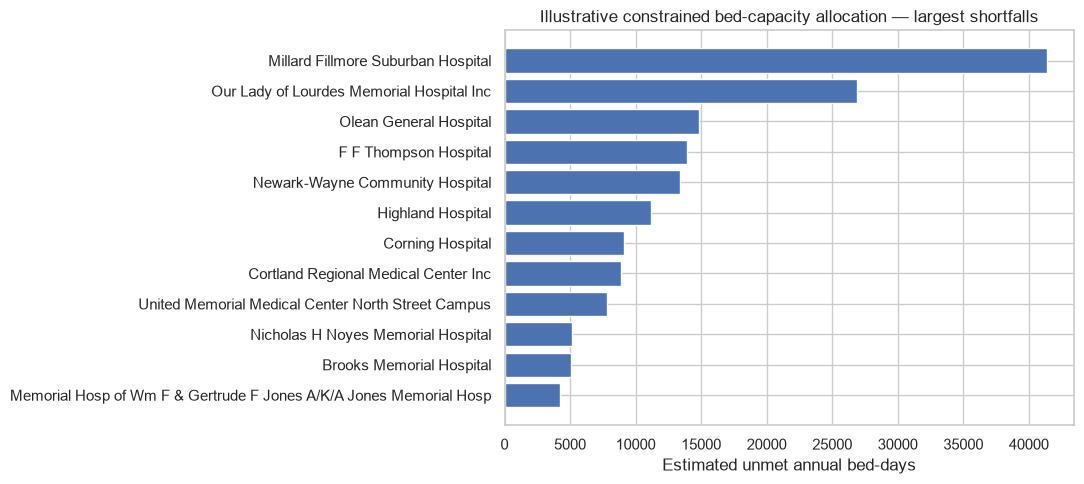

CAUTION: Not a forecast of real-time occupancy or operational bed availability.


In [ ]:
# 29. Optimize integer staffed beds: minimize priority-weighted unmet bed-days
# Variables = [beds allocated to hospital i (integers), unmet bed-days i (continuous)].
# For every hospital i:
#   target_occupancy * 365 * beds_i + unmet_i >= reference_bed_days_i
# Also: sum_i beds_i <= TOTAL_BEDS_AVAILABLE; minimum_beds_i <= beds_i.

n_hosp = len(hospital_reference)
demand = hospital_reference.reference_bed_days.to_numpy(dtype=float)
weights = hospital_reference.priority_weight.to_numpy(dtype=float)
min_beds = hospital_reference.minimum_beds.to_numpy(dtype=float)
max_beds = hospital_reference.reference_beds_needed.to_numpy(dtype=float)

objective = np.r_[np.zeros(n_hosp), weights]
A_total = np.r_[np.ones(n_hosp), np.zeros(n_hosp)].reshape(1, -1)
A_cover = np.column_stack([-DAYS_PER_YEAR * TARGET_OCCUPANCY * np.eye(n_hosp),
                            -np.eye(n_hosp)])
constraints = [
    LinearConstraint(A_total, -np.inf, TOTAL_BEDS_AVAILABLE),
    LinearConstraint(A_cover, -np.inf * np.ones(n_hosp), -demand)
]
optimization = milp(
    c=objective,
    integrality=np.r_[np.ones(n_hosp, dtype=int), np.zeros(n_hosp, dtype=int)],
    bounds=Bounds(lb=np.r_[min_beds, np.zeros(n_hosp)],
                  ub=np.r_[max_beds, np.full(n_hosp, np.inf)]),
    constraints=constraints,
    options={'time_limit': 60}
)
if optimization.x is None:
    raise RuntimeError(f'Bed allocation could not be solved: {optimization.message}')
if not optimization.success:
    print('Solver returned a feasible solution but did not certify optimality:',
          optimization.message)

hospital_reference['allocated_beds'] = np.rint(optimization.x[:n_hosp]).astype(int)
hospital_reference['unmet_bed_days'] = np.maximum(
    demand - DAYS_PER_YEAR * TARGET_OCCUPANCY *
    hospital_reference['allocated_beds'].to_numpy(), 0.)
hospital_reference['met_demand_pct'] = 100 * (1 -
    hospital_reference['unmet_bed_days'] / np.maximum(demand, 1))

summary = {
    'beds_allocated': int(hospital_reference.allocated_beds.sum()),
    'beds_available': TOTAL_BEDS_AVAILABLE,
    'reference_bed_days': round(float(demand.sum())),
    'unmet_bed_days': round(float(hospital_reference.unmet_bed_days.sum())),
    'demand_coverage_%': round(100 * (1 - hospital_reference.unmet_bed_days.sum() /
                                      max(demand.sum(), 1)), 2)
}
print('Illustrative optimization scenario:', summary)
display(hospital_reference.sort_values('unmet_bed_days', ascending=False).head(15).round(2))

fig, ax = plt.subplots(figsize=(11, 5))
subset = hospital_reference.sort_values('unmet_bed_days', ascending=False).head(12)
ax.barh(subset.index.astype(str), subset.unmet_bed_days)
ax.invert_yaxis()
ax.set(xlabel='Estimated unmet annual bed-days',
       title='Illustrative constrained bed-capacity allocation — largest shortfalls')
plt.tight_layout(); plt.show()
print('CAUTION: Not a forecast of real-time occupancy or operational bed availability.')


#### Results: optimized bed allocation (illustrative MILP)

| Metric | Value |
|---|---:|
| Beds allocated / available | **5,449 / 5,449** (budget fully used) |
| Reference bed-days (demand) | 1,869,351 |
| Unmet bed-days | **179,289** |
| Demand coverage | **90.41%** |

- Coverage (90.41%) is essentially the 90% bed budget, so nearly all allocated capacity is productively used. The small excess over 90% comes from rounding bed requirements up to whole beds.
- **Shortfalls fall on hospitals with lower predicted LOS.** Every hospital in the top-15 shortfall list (for example Millard Fillmore Suburban, Our Lady of Lourdes, Olean General, F F Thompson, Newark-Wayne, Highland, Corning, Cortland) has a predicted mean LOS of 3.3 to 4.3 days, below the median hospital (about 4.8 days, as implied by the priority weights).
- That pattern is built into the scenario: the objective minimizes **priority-weighted** unmet bed-days, and weights rise with predicted LOS, so the solver protects higher-LOS hospitals first.

> **Caution:** this is a scenario, not a recommendation. SPARCS contains no verified staffed-bed capacity, staffing or arrival-time data. Replace the occupancy target, budget fraction, minimum-allocation rule and priority weights with real operational inputs before drawing conclusions.

<a id="sec11"></a>
## 11. Summary, limitations and next steps

### Key findings

1. **LOS is highly skewed.** Mean 5.31 vs. median 3 days; 1.43% of stays exceed 30 days and drive most of the variance.
2. **Admission-time information has limited predictive power.** The best admission-time model (HistGB Poisson, Set A) reaches test MAE 3.61 days and R² 0.09, a roughly 10% MAE improvement over predicting the mean.
3. **Model choice matters little.** The four best Set A models are within 0.05 on the selection score; tuning and regularization added almost nothing.
4. **Facility, age, payer and admission type are the most influential admission-time features**, in both the linear coefficients and the SHAP analysis.
5. **Long stays are systematically underpredicted** (about -28 days for stays over 20 days). Tail weighting reduces this but harms accuracy for common stays.
6. **Total bed-days are predicted accurately (-0.22% error) but service-line totals are not** (errors from -39% to +32% across service lines with 1,000+ test discharges), because diagnosis is not available at admission.
7. **Clinical codes would help a lot, but only retrospectively.** Adding diagnosis group and severity raises validation R² from 0.09 to 0.23 and 0.36.
8. **The optimization scenario** allocates 5,449 beds to cover 90.4% of 1.87 million reference bed-days, with shortfalls concentrated in lower-LOS hospitals by construction of the weights.

### Limitations

- **Within-year validation only.** A random 2015 split does not measure performance on future years or unseen hospitals.
- **Field availability.** Even Set A fields (payer, zip prefix, facility ID) must be confirmed as available at the moment of prediction in a real admission workflow.
- **Top-coded stays.** 295 stays are recorded as `120 +`, so their true LOS and bed-days are higher than shown.
- **No patient ID.** Repeat admissions by the same patient may appear in different partitions, which cannot be ruled out.
- **Associations, not causes.** Coefficients and SHAP values describe model behavior; differences by race, gender or payer should not be interpreted causally.
- **Scenario optimization.** Bed capacity, occupancy, minimums and priority weights are assumptions.

### Suggested next steps

- Obtain multi-year SPARCS data and validate **out of time** (train on earlier years, test on later years).
- Check whether a working diagnosis or triage category is available at admission; Sets B and C show how much it could add.
- Model the long tail directly with quantile or distributional approaches rather than a single point estimate.
- Replace the scenario inputs with real staffed-bed, staffing and arrival data before using the optimization for decisions.
- Review the use of race and ethnicity for fairness and necessity.